# Customer Review Classification with TensorFlow

## 1. Project Overview

### 1.1. Business Problem

Online stores receive many customer reviews every day.
These reviews contain useful information about customer experiences and product quality.

Reading all reviews manually takes a lot of time.

In this project, we will build a Natural Language Processing
(NLP) model to predict whether a customer recommends a product
based on their written review.

### 1.2. Project Objectives

The main objectives of this project are:

- Explore and understand customer review data.
- Prepare text data for machine learning.
- Build a baseline classification model.
- Train deep learning models using TensorFlow and Keras.
- Compare models using classification metrics.
- Select and save the best model.
- Build a prediction API with FastAPI.
- Create a user interface with Streamlit.

### 1.3. Target Variable

The target variable is `Recommended IND`.

- 1: The customer recommends the product.
- 0: The customer does not recommend the product.

This is a binary text classification problem.

## 2. Data Understanding

### 2.1. Loading the Dataset

In this section, we will load the customer review dataset.

First, we will examine the number of rows and columns.
Then, we will look at sample records and explore the
available features.

This step helps us understand the dataset before
data cleaning and model development.

In [79]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import unicodedata
import gc
import optuna
import json
import joblib
import sklearn

from pathlib import Path

%matplotlib inline

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay
)
from sklearn.base import clone

from tensorflow.keras import Model, layers
from tensorflow.keras.layers import TextVectorization, Embedding
from tensorflow.keras.callbacks import EarlyStopping

# Pandas display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 180)
pd.set_option("display.precision", 4)
pd.set_option("display.expand_frame_repr", False)
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

project_root = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

data_path = (
    project_root
    / "data"
    / "raw"
    / "Womens Clothing E-Commerce Reviews.csv"
)

In [3]:
df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (23486, 11)


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comfortable,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,"Love this dress! it's sooo pretty. i happened to find it in a store, and i...",5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and really wanted it to work for me. i ...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to the adjustable front tie. it is ...,5,1,6,General,Tops,Blouses


### 2.2. Dataset Structure and Missing Values

Before training a model, we need to understand the structure
and quality of our dataset.

In this step, we will:

- Check the data types of each feature.
- Calculate the number of missing values.
- Calculate the percentage of missing values.
- Identify features that may require data cleaning.

Missing values are important because they can affect
our analysis and model performance.

Our main focus is the `Review Text` feature and the
`Recommended IND` target variable.

In [4]:
# Dataset information 
df.info()

# Missing value analysis
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100
})

missing_summary = (
    missing_summary
    .sort_values("missing_pct", ascending=False)
    .round(2)
)

display(missing_summary)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Unnamed: 0               23486 non-null  int64 
 1   Clothing ID              23486 non-null  int64 
 2   Age                      23486 non-null  int64 
 3   Title                    19676 non-null  object
 4   Review Text              22641 non-null  object
 5   Rating                   23486 non-null  int64 
 6   Recommended IND          23486 non-null  int64 
 7   Positive Feedback Count  23486 non-null  int64 
 8   Division Name            23472 non-null  object
 9   Department Name          23472 non-null  object
 10  Class Name               23472 non-null  object
dtypes: int64(6), object(5)
memory usage: 2.0+ MB


,missing_count,missing_pct
Title,3810,16.22
Review Text,845,3.60
Division Name,14,0.06
Department Name,14,0.06
Class Name,14,0.06
Unnamed: 0,0,0.00
Clothing ID,0,0.00
Age,0,0.00
Rating,0,0.00
Recommended IND,0,0.00


### 2.3. Data Cleaning

Our main goal is to predict product recommendations
using customer review texts.

We will use only two columns:

- `Review Text`: The input feature.
- `Recommended IND`: The target variable.

Some customer reviews are missing. We will remove
these records because they do not contain useful text
information for our NLP model.

We will also remove empty reviews and extra spaces
at the beginning and end of each text.

The original dataset will remain unchanged.

In [5]:
# Select the required columns
df_model = df[
    ["Review Text", "Recommended IND"]
].copy()

# Rename columns
df_model = df_model.rename(
    columns = {
        "Review Text": "review_text",
        "Recommended IND": "target"
    }
)

# Remove missing reviews
df_model = df_model.dropna(subset=["review_text"])

# Remove leading and trailing spaces
df_model["review_text"] = df_model["review_text"].str.strip()

# Remove empty reviews
df_model = df_model.loc[
    df_model["review_text"].ne("")
].copy()

# Check the cleaned dataset
print("Original shape:", df.shape)
print("Cleaned shape:", df_model.shape)
print("Removed rows:", len(df) - len(df_model))

display(df_model.head())

Original shape: (23486, 11)
Cleaned shape: (22641, 2)
Removed rows: 845


,review_text,target
0,Absolutely wonderful - silky and sexy and comfortable,1
1,"Love this dress! it's sooo pretty. i happened to find it in a store, and i...",1
2,I had such high hopes for this dress and really wanted it to work for me. i ...,0
3,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time...",1
4,This shirt is very flattering to all due to the adjustable front tie. it is ...,1


### 2.4. Target Variable Analysis

The target variable is `target`, which shows whether
a customer recommends a product.

- 0: Not Recommended
- 1: Recommended

In this section, we will examine the distribution
of the target variable.

We will calculate the number and percentage of
reviews in each class.

We will also visualize the class distribution.

This analysis is important because an imbalanced
dataset can affect model training and evaluation.

If one class is much larger than the other,
accuracy alone may not be a reliable metric.

In [6]:
# Calculate class counts
class_counts = (
    df_model["target"]
    .value_counts()
    .sort_index()
)

# Calculate class percentages

class_pct = (
    df_model["target"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

class_summary = pd.DataFrame({
    "count": class_counts,
    "percentage": class_pct.round(2)
})

display(class_summary)

,count,percentage
target,,
0,4101,18.11
1,18540,81.89


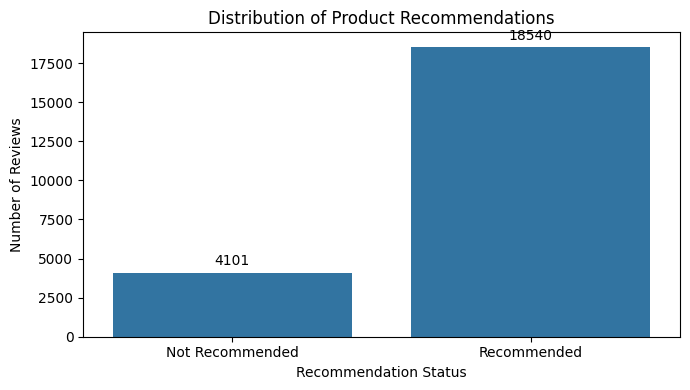

In [7]:
fig, ax = plt.subplots(figsize = (7,4))

sns.countplot(
    data = df_model,
    x = "target",
    order = [0,1],
    ax = ax
)

ax.set_title("Distribution of Product Recommendations")
ax.set_xlabel("Recommendation Status")
ax.set_ylabel("Number of Reviews")

ax.set_xticks([0, 1])
ax.set_xticklabels(["Not Recommended", "Recommended"])

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

#### Key Findings: Target Distribution

The dataset has an imbalanced target distribution.

- 81.89% of customers recommend the product.
- 18.11% of customers do not recommend the product.

The positive class is much larger than the negative class.

A model that always predicts the positive class can achieve
81.89% accuracy. However, it cannot identify negative reviews.

For this reason, we will evaluate our models using
precision, recall, F1-score, and the confusion matrix.

We will also use stratified data splitting to keep similar
class distributions in our training and evaluation datasets.

### 2.5. Text Length Analysis

Text length is an important feature in NLP projects.

Customer reviews can have different lengths. Some reviews
contain only a few words, while others are much longer.

In this section, we will:

- Calculate the number of words in each review.
- Calculate the number of characters in each review.
- Examine the distribution of review lengths.
- Identify short and long reviews.

This analysis will help us understand the text data
and choose suitable parameters for text vectorization.

In [8]:
# Calculate text length features
df_model["word_count"] = (
    df_model["review_text"].str.split().str.len()
)

df_model["char_count"] = (
    df_model["review_text"].str.len()
)

# Descriptive statistics
length_summary = df_model[
    ["word_count", "char_count"]
].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(length_summary.round(2))

,word_count,char_count
count,"22,641.00","22,641.00"
mean,60.20,308.69
std,28.53,143.94
min,2.00,9.00
25%,36.00,186.00
50%,59.00,301.00
75%,88.00,459.00
90%,98.00,500.00
95%,101.00,500.00
99%,106.00,502.00


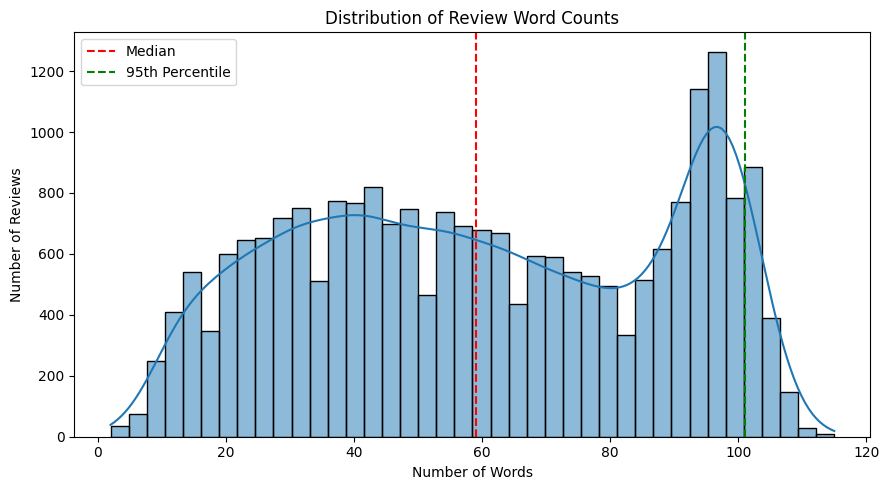

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=df_model,
    x="word_count",
    bins=40,
    kde=True,
    ax=ax
)

ax.axvline(
    df_model["word_count"].median(),
    color="red",
    linestyle="--",
    label="Median"
)

ax.axvline(
    df_model["word_count"].quantile(0.95),
    color="green",
    linestyle="--",
    label="95th Percentile"
)

ax.set_title("Distribution of Review Word Counts")
ax.set_xlabel("Number of Words")
ax.set_ylabel("Number of Reviews")
ax.legend()

plt.tight_layout()
plt.show()

#### Key Findings: Text Length

The dataset contains 22,641 customer reviews.

- The average review length is 60.20 words.
- The median review length is 59 words.
- 75% of reviews contain 88 words or fewer.
- 95% of reviews contain 101 words or fewer.
- The longest review contains 115 words.

The histogram shows two main groups of review lengths.

Many reviews contain around 30–50 words, while another
large group contains around 90–100 words.

These results will help us choose a suitable sequence
length for our deep learning models.

We will make the final decision after text vectorization.

### 2.6. Review Length by Target Class

In this section, we will compare review lengths between
customers who recommend products and those who do not.

We want to answer the following questions:

- Do positive and negative classes have different review lengths?
- Which class has a higher average word count?
- Are there important differences in their distributions?

This analysis may help us understand how customer
feedback patterns differ between the two classes.

In [10]:
length_by_target = (
    df_model.groupby("target")["word_count"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max"
    )
    .round(2)
)

display(length_by_target)

,count,mean,median,std,min,max
target,,,,,,
0,4101,62.00,61.00,27.01,3,115
1,18540,59.80,58.00,28.85,2,115


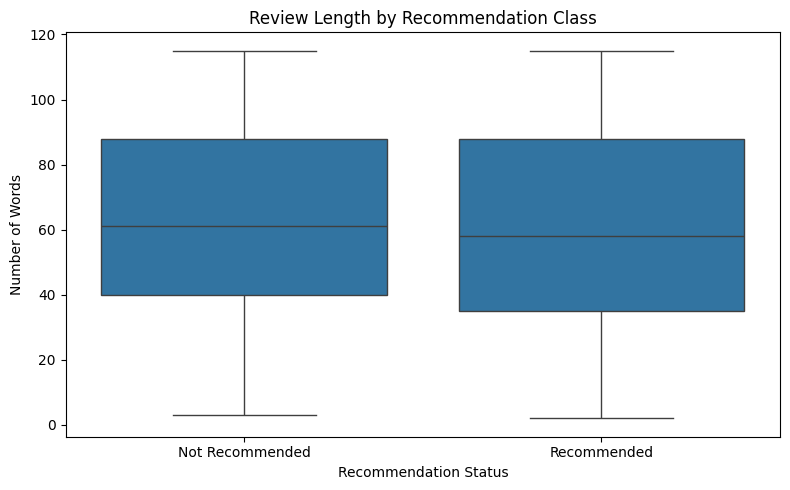

In [11]:
fig, ax = plt.subplots(figsize=(8,5))

sns.boxplot(
    data=df_model,
    x="target",
    y="word_count",
    order=[0,1],
    showfliers=False,
    ax=ax
)

ax.set_title("Review Length by Recommendation Class")
ax.set_xlabel("Recommendation Status")
ax.set_ylabel("Number of Words")

ax.set_xticks([0, 1])
ax.set_xticklabels(["Not Recommended", "Recommended"])

plt.tight_layout()
plt.show()

#### Key Findings: Review Length by Target

The results show that both classes have similar
review lengths.

- Not recommended reviews contain 62 words on average.
- Recommended reviews contain 59.8 words on average.
- The difference between the two groups is small.
- Both classes have similar word count distributions.

These findings suggest that review length alone may
not be enough to predict product recommendations.

The words and their meanings are likely to provide
more useful information for our NLP models.

### 2.7. Word Frequency Analysis

In this section, we will examine the most common words
in customer reviews.

We will compare word usage between the two target classes.

Our main goals are:

- Identify frequently used words in customer reviews.
- Compare word usage between recommendation classes.
- Understand which words may provide useful information
  for text classification.

Because the dataset is imbalanced, we will compare the
percentage of reviews containing each word.

This will help us make a fairer comparison between classes.

In [12]:
# Create a vectorizer for exploratory analysis

# It creates a vocabulary from the words found in the texts and converts the comments into a numerical matrix.
vectorizer = CountVectorizer(
    # İngilizcedeki yaygın stop words kelimelerini bu keşif analizinde çıkarır.
    stop_words = "english",
    # It retains words that appear in at least 10 different comments within the dataset.
    min_df=10,
    # Instead of tracking how many times a word appears in a comment, it records whether or not it appears.
    binary=True
)

# Convert text into a document-term matrix
word_matrix = vectorizer.fit_transform(
    df_model["review_text"]
)

# Get vocabulary
words = vectorizer.get_feature_names_out()


# Create target masks
target_values = df_model["target"].to_numpy()

negative_mask = target_values == 0
positive_mask = target_values == 1

# Calculate word prevalence in each class
negative_pct = (
    np.asarray(word_matrix[negative_mask].mean(axis=0))
    .ravel()*100
)

positive_pct = (
    np.asarray(word_matrix[positive_mask].mean(axis=0))
    .ravel() * 100
)

# Create comparison table
word_summary = pd.DataFrame({
    "word": words,
    "not_recommended_pct": negative_pct,
    "recommended_pct": positive_pct
})


print("Most common words in negative reviews:")

display(
    word_summary.nlargest(
        15, "not_recommended_pct"
    ).round(2)
)

print("Most common words in positive reviews:")

display(
    word_summary.nlargest(
        15, "recommended_pct"
    ).round(2)
)

Most common words in negative reviews:


,word,not_recommended_pct,recommended_pct
1623,like,34.43,23.79
1127,fit,27.02,27.47
935,dress,25.82,27.09
1528,just,25.07,19.95
1066,fabric,24.80,16.91
2486,size,22.51,30.59
1653,look,20.14,14.54
1673,love,19.58,35.70
1906,ordered,18.61,14.58
2199,really,18.19,14.22


Most common words in positive reviews:


,word,not_recommended_pct,recommended_pct
1673,love,19.58,35.70
2486,size,22.51,30.59
1127,fit,27.02,27.47
935,dress,25.82,27.09
3065,wear,16.34,26.22
1300,great,11.68,25.46
1623,like,34.43,23.79
1528,just,25.07,19.95
651,color,15.61,18.44
1983,perfect,4.56,17.24


#### Key Findings: Word Frequency

The analysis shows differences in word usage between
the two recommendation classes.

- Words such as "love", "great", and "perfect" appear
  more often in recommended reviews.
- Words such as "fabric" and "way" appear more often
  in not recommended reviews.
- The word "fit" has a similar frequency in both classes.
- The word "like" appears more often in not recommended
  reviews, which is an interesting result.

A single word does not always explain the meaning
of a complete sentence.

For example, "I like it" and "I don't like it"
have different meanings.

Our deep learning models will try to learn useful
patterns from word sequences and their context.

### 2.8. Word Prevalence Differences

In this section, we will compare word prevalence
between the two recommendation classes.

We will calculate the difference in percentage points
for each word.

A positive difference means that a word appears more
often in recommended reviews.

A negative difference means that a word appears more
often in not recommended reviews.

We will visualize the words with the largest differences.

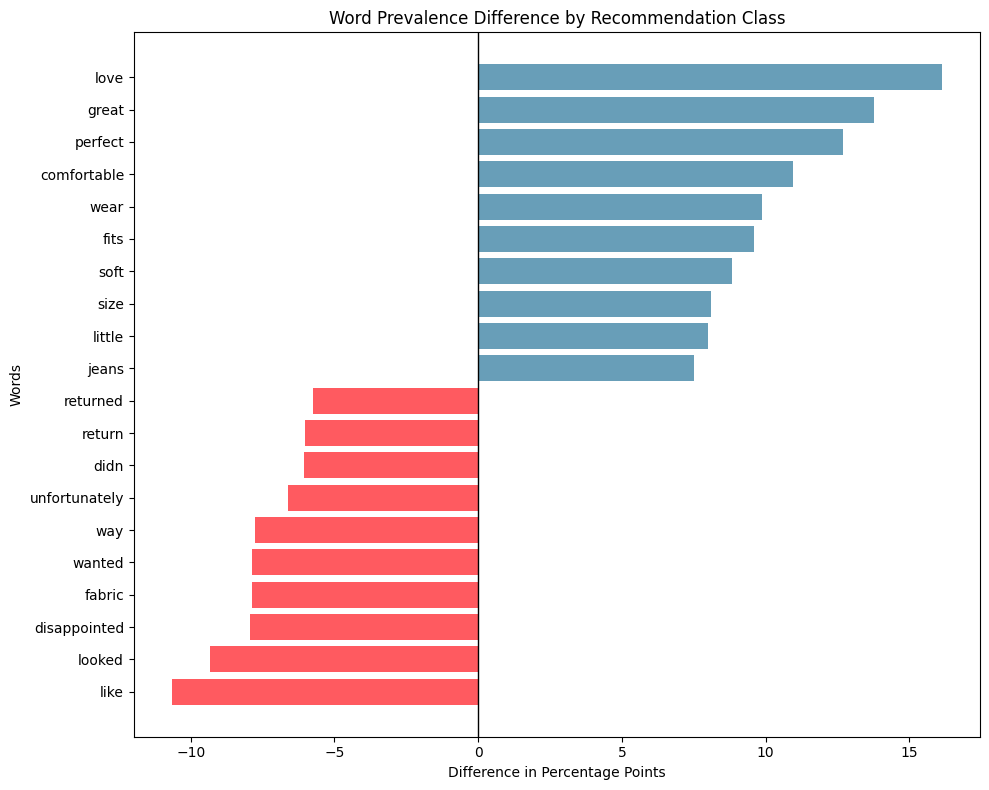

In [13]:
# Calculate percentage point differences
word_summary["difference_pp"] = (
    word_summary["recommended_pct"] - word_summary["not_recommended_pct"]
)

# Select words with the largest differences
positive_words = word_summary.nlargest(
    10, "difference_pp"
)

negative_words = word_summary.nsmallest(
    10, "difference_pp"
)

# Combine results
comparison = pd.concat([
    negative_words,
    positive_words
]).sort_values("difference_pp")

# Define colors
colors = [
    "#689EB8" if value > 0 else "#FF5A60"
    for value in comparison["difference_pp"]
]

# Plot results
fig, ax = plt.subplots(figsize=(10, 8))

ax.barh(
    comparison["word"],
    comparison["difference_pp"],
    color=colors
)

ax.axvline(0, color="black", linewidth=1)

ax.set_title("Word Prevalence Difference by Recommendation Class")
ax.set_xlabel("Difference in Percentage Points")
ax.set_ylabel("Words")

plt.tight_layout()
plt.show()


#### Key Findings: Word Prevalence Differences

The results show clear differences in word usage
between the two recommendation classes.

- Words such as "love", "great", and "perfect" are
  more common in recommended reviews.
- Words such as "disappointed", "return", and
  "unfortunately" are more common in not recommended reviews.
- The word "like" is more common in not recommended reviews.

Word meaning can change depending on other words
in the sentence.

For example, "like" and "don't like" express
different opinions.

For this reason, we will also examine groups of words.

### 2.9. Bigram Analysis

A bigram is a group of two consecutive words.

Single words may not explain the full meaning
of a customer review.

For example, "good quality" and "poor quality"
describe different product experiences.

In this section, we will:

- Extract common two-word phrases from reviews.
- Compare bigram usage between recommendation classes.
- Identify phrases that may help distinguish the classes.

We will keep stop words because words such as
"not" and "don't" can change the meaning of a sentence.

In [14]:
# Create bigram vectorizer
bigram_vectorizer = CountVectorizer(
    # It forms only two-word phrases.
    ngram_range=(2,2),
    stop_words=None,
    # We take the statements that appear in at least 15 different interpretations.
    min_df=15,
    # We are assessing whether a statement constitutes a piece of commentary.
    binary=True,
    # We keep English words and expressions such as "don't" and "didn't" intact as much as possible.
    token_pattern=r"(?u)\b[a-zA-Z]+(?:['’][a-zA-Z]+)*\b"
)

# Create document-bigram matrix
bigram_matrix = bigram_vectorizer.fit_transform(
    df_model["review_text"]
)

bigrams = bigram_vectorizer.get_feature_names_out()

# Calculate bigram prevalence by class
negative_bigram_pct = (
    np.asarray(bigram_matrix[negative_mask].mean(axis=0))
    .ravel() * 100
)

positive_bigram_pct = (
    np.asarray(bigram_matrix[positive_mask].mean(axis=0))
    .ravel() * 100
)

# Create bigram summary
bigram_summary = pd.DataFrame({
    "bigram": bigrams,
    "not_recommended_pct": negative_bigram_pct,
    "recommended_pct": positive_bigram_pct
})

bigram_summary["difference_pp"] = (
    bigram_summary["recommended_pct"]
    - bigram_summary["not_recommended_pct"]
)

# Display the most distinctive bigrams
print("Top bigrams in not recommended reviews:")

display(
    bigram_summary.nsmallest(
        15, "difference_pp"
    ).round(2)
)

print("Top bigrams in recommended reviews:")

display(
    bigram_summary.nlargest(
        15, "difference_pp"
    ).round(2)
)

Top bigrams in not recommended reviews:


,bigram,not_recommended_pct,recommended_pct,difference_pp
4768,it was,20.99,9.53,-11.46
4116,i was,18.41,9.67,-8.74
1875,but the,14.46,6.93,-7.53
10096,wanted to,8.27,1.33,-6.94
6313,of the,20.31,13.59,-6.73
9517,to love,6.56,0.61,-5.94
4336,in the,30.33,24.39,-5.94
5187,like a,10.61,5.03,-5.58
10202,was so,6.73,1.36,-5.37
8667,the fabric,15.02,9.97,-5.05


Top bigrams in recommended reviews:


,bigram,not_recommended_pct,recommended_pct,difference_pp
4035,i love,8.66,18.53,9.87
154,a little,6.41,14.21,7.80
4380,is a,11.00,18.25,7.26
5491,love this,5.90,11.13,5.23
9556,to size,3.19,8.20,5.01
9583,to wear,5.44,10.29,4.85
10571,with a,6.78,11.50,4.73
5488,love the,7.24,11.90,4.66
4676,it is,17.61,22.22,4.62
3964,i bought,4.73,9.30,4.57


#### Key Findings: Bigram Analysis

The bigram analysis shows differences between
recommended and not recommended reviews.

- Phrases such as "i love", "love this", and "it fits"
  appear more often in recommended reviews.
- Phrases such as "wanted to", "to return", and
  "going back" appear more often in not recommended reviews.
- Some common phrases, such as "it was", do not have
  a clear positive or negative meaning.

These results show that word combinations can provide
useful information for text classification.

However, two words may not explain the full meaning
of a sentence.

We will use deep learning models to learn patterns
from longer word sequences.

### 2.10. Duplicate Review Analysis

Duplicate reviews can affect model evaluation.

If the same review appears in both the training
and test datasets, the model may produce
unrealistically good results.

In this section, we will:

- Identify repeated review texts.
- Count the number of duplicate reviews.
- Check whether identical texts have different labels.

This analysis will help us prepare a reliable
dataset for model training and evaluation.

In [15]:
# Normalize review texts for duplicate detection
review_key = (
    df_model["review_text"]
    # It helps us compare texts regardless of case differences.
    .str.casefold()
    # Reduces multiple spaces to a single space.
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Identify duplicated reviews
duplicate_mask = review_key.duplicated(keep=False)

# Check conflicting target labels
conflicting_labels = (
    df_model.assign(review_key=review_key)
    .groupby("review_key")["target"]
    .nunique()
)


conflicting_labels = conflicting_labels[
    conflicting_labels > 1
]

# Display results
print("Total reviews:", len(df_model))
print("Rows with repeated texts:", duplicate_mask.sum())
print("Unique repeated texts:", review_key[duplicate_mask].nunique())
print("Texts with conflicting labels:", len(conflicting_labels))

display(
    df_model.loc[
        duplicate_mask,
        ["review_text", "target"]
    ].head(10)
)

Total reviews: 22641
Rows with repeated texts: 13
Unique repeated texts: 6
Texts with conflicting labels: 0


,review_text,target
1891,I purchased this and another eva franco dress during retailer's recent 20% o...,0
7639,Perfect fit and i've gotten so many compliments. i buy all my suits from her...,1
9447,"Love, love these jeans. being short they come right to my ankle. super soft ...",1
10067,Perfect fit and i've gotten so many compliments. i buy all my suits from her...,1
10137,"I bought this shirt at the store and after going home and trying it on, i pr...",1
10708,"Lightweight, soft cotton top and shorts. i think it's meant to be a beach co...",1
11074,"Lightweight, soft cotton top and shorts. i think it's meant to be a beach co...",1
12526,I purchased this and another eva franco dress during retailer's recent 20% o...,0
13354,Perfect fit and i've gotten so many compliments. i buy all my suits from her...,1
14275,"I bought this shirt at the store and after going home and trying it on, i pr...",1


#### Key Findings: Duplicate Reviews

The dataset contains 13 rows with repeated review texts.

These rows represent 6 unique review texts.
There are no conflicting target labels.

We will keep one record for each repeated text
and remove the extra 7 records.

This step helps us prevent data leakage between
training, validation, and test datasets.

In [16]:
# Remove repeated reviews
df_clean = (
    df_model.loc[
        ~review_key.duplicated(keep="first"),
        ["review_text", "target"]
    ]
    .reset_index(drop=True)
)

print("Before:", len(df_model))
print("After:", len(df_clean))
print("Removed:", len(df_model) - len(df_clean))

Before: 22641
After: 22634
Removed: 7


## 3. Data Preparation for Modeling

### 3.1. Train, Validation, and Test Split

Before training our models, we will divide the
cleaned dataset into three parts:

- Training set (80%): Used to train the models.
- Validation set (10%): Used to compare models and tune parameters.
- Test set (10%): Used for the final evaluation.

We will use stratified splitting to keep a similar
target distribution in each dataset.

We will also set a random seed to make our
experiments more reproducible.

The test set will not be used during model training
or model selection.

In [17]:
# First split: 80% training, 20% temporary
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.20,
    stratify=df_clean["target"],
    random_state=RANDOM_STATE
)

# Second split: 10% validation, 10% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["target"],
    random_state=RANDOM_STATE
)

# Display dataset sizes
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Training: (18107, 2)
Validation: (2263, 2)
Test: (2264, 2)


### 3.2. Split Validation

After splitting the dataset, we will check
the number of observations in each dataset.

We will also compare the target distributions.

Similar class percentages across the datasets
will show that stratified splitting worked as expected.

In [18]:
split_summary = []

for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    class_pct = (
        data["target"]
        .value_counts(normalize=True)
        .mul(100)
    )

    split_summary.append({
        "dataset": name,
        "rows": len(data),
        "not_recommended_pct": class_pct.get(0, 0),
        "recommended_pct": class_pct.get(1, 0)
    })

split_summary = pd.DataFrame(split_summary)

display(split_summary.round(2))

,dataset,rows,not_recommended_pct,recommended_pct
0,Train,18107,18.11,81.89
1,Validation,2263,18.12,81.88
2,Test,2264,18.11,81.89


## 4. Baseline Machine Learning Model

### 4.1. TF-IDF and Logistic Regression

Before building deep learning models, we will train
a simple machine learning model.

We will use two methods:

- TF-IDF to convert text into numerical features.
- Logistic Regression to predict recommendation classes.

TF-IDF gives weights to words based on their frequency
in a review and across the training dataset.

Logistic Regression uses these numerical features
to estimate the probability of each class.

This model will be our baseline.

Later, we will compare its performance with
TensorFlow deep learning models.

To prevent data leakage, TF-IDF will learn its
vocabulary only from the training data.

In [19]:
# Create baseline pipeline
baseline_pipeline = Pipeline(
    steps=[
        (
            "tfidf",
            TfidfVectorizer(
                # It uses single words and bigrams.
                ngram_range=(1,2),
                # It retains the expressions that appear in at least 3 training comments.
                min_df=3,
                # Extracts the phrases found in more than 95% of the training comments.
                max_df=0.95,
                # It scales word frequency logarithmically.
                sublinear_tf=True,
                # It helps preserve English words and expressions such as "don't."
                token_pattern=r"(?u)\b[a-zA-Z]+(?:['’][a-zA-Z]+)*\b"
            )
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=RANDOM_STATE
            )
        )
    ]
)

# Train baseline model
baseline_pipeline.fit(
    train_df["review_text"],
    train_df["target"]
)

# Check vocabulary size
vocabulary = baseline_pipeline.named_steps[
    "tfidf"
].get_feature_names_out()

print("Training samples:", len(train_df))
print("Vocabulary size:", len(vocabulary))
print("Model classes:", baseline_pipeline.classes_)

Training samples: 18107
Vocabulary size: 46772
Model classes: [0 1]


### 4.2. Baseline Model Evaluation

After training our baseline model, we will evaluate
its performance on the validation dataset.

We will use the following evaluation metrics:

- Accuracy: The percentage of correct predictions.
- Precision: How many predicted samples are correct.
- Recall: How many actual samples are correctly identified.
- F1-score: The balance between precision and recall.
- Macro F1-score: The average F1-score across both classes.

Our dataset is imbalanced. Therefore, accuracy alone
is not enough to evaluate model performance.

We will pay special attention to the model's ability
to identify customers who do not recommend products.

The test dataset will remain unused until the final
model evaluation.

In [20]:
# Validation features and target
X_val = val_df["review_text"]
y_val = val_df["target"]

# Predict validation classes
baseline_val_pred = baseline_pipeline.predict(X_val)

# Calculate evaluation metrics
baseline_accuracy = accuracy_score(
    y_val,
    baseline_val_pred
)

baseline_macro_f1 = f1_score(
    y_val,
    baseline_val_pred,
    average="macro"
)

print(f"Validation Accuracy: {baseline_accuracy:.4f}")
print(f"Validation Macro F1: {baseline_macro_f1:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_val,
        baseline_val_pred,
        labels=[0, 1],
        target_names=[
            "Not Recommended",
            "Recommended"
        ],
        digits=4,
        zero_division=0
    )
)

Validation Accuracy: 0.8816
Validation Macro F1: 0.7687

Classification Report:
                 precision    recall  f1-score   support

Not Recommended     0.7610    0.5049    0.6070       410
    Recommended     0.8980    0.9649    0.9303      1853

       accuracy                         0.8816      2263
      macro avg     0.8295    0.7349    0.7687      2263
   weighted avg     0.8732    0.8816    0.8717      2263



#### Key Findings: Baseline Model Performance

Our baseline model achieved the following results:

- Validation Accuracy: 88.16%
- Macro F1-score: 76.87%
- Not Recommended Recall: 50.49%
- Recommended Recall: 96.49%

The model performs well on recommended reviews.

However, it correctly identifies only about half
of the not recommended reviews.

This is an important limitation because our
dataset has an imbalanced class distribution.

We will test class weighting to improve the
model's performance on the minority class.

### 4.4. Handling Class Imbalance

Our baseline model has difficulty identifying
not recommended reviews.

One possible reason is class imbalance.

To address this problem, we will train another
Logistic Regression model with balanced class weights.

This method gives higher weight to the minority class
during model training.

We want to improve minority-class recall without
reducing overall model quality too much.

We will compare this model with our original baseline
using the same validation dataset.

In [21]:
balanced_pipeline = clone(baseline_pipeline)

balanced_pipeline.set_params(
    classifier__class_weight="balanced"
)

# Train the balanced model
balanced_pipeline.fit(
    train_df["review_text"],
    train_df["target"]
)

# Make predictions
balanced_val_pred = balanced_pipeline.predict(
    val_df["review_text"]
)

# Evaluate the model
balanced_accuracy = accuracy_score(
    y_val,
    balanced_val_pred
)

balanced_macro_f1 = f1_score(
    y_val,
    balanced_val_pred,
    average="macro"
)

print(f"Validation Accuracy: {balanced_accuracy:.4f}")
print(f"Validation Macro F1: {balanced_macro_f1:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_val,
        balanced_val_pred,
        labels=[0, 1],
        target_names=[
            "Not Recommended",
            "Recommended"
        ],
        digits=4,
        zero_division=0
    )
)

Validation Accuracy: 0.8763
Validation Macro F1: 0.8168

Classification Report:
                 precision    recall  f1-score   support

Not Recommended     0.6152    0.8463    0.7125       410
    Recommended     0.9629    0.8829    0.9212      1853

       accuracy                         0.8763      2263
      macro avg     0.7891    0.8646    0.8168      2263
   weighted avg     0.8999    0.8763    0.8834      2263



#### Key Findings: Balanced Logistic Regression

The balanced model improved the classification of
not recommended reviews.

- Accuracy decreased slightly from 88.16% to 87.63%.
- Macro F1-score increased from 76.87% to 81.68%.
- Minority-class recall increased from 50.49% to 84.63%.
- Minority-class precision decreased from 76.10% to 61.52%.

The balanced model identifies more customers who
do not recommend products.

However, it also makes more incorrect predictions
for customers who recommend products.

This shows a trade-off between precision and recall.

Based on Macro F1-score, the balanced model is
currently our preferred baseline.

### 4.5. Classification Threshold Optimization

Logistic Regression predicts the probability
of each recommendation class.

By default, the classification threshold is 0.50.

However, this threshold may not provide the best
results for an imbalanced dataset.

In this section, we will:

- Test different classification thresholds.
- Calculate Macro F1-score for each threshold.
- Compare minority-class precision and recall.
- Find a suitable threshold using validation data.

We will not use the test dataset during
threshold optimization.

In [22]:
# Get predicted probabilities for class 1
# With [:, 1], we retrieve only the probabilities belonging to the Recommended (1) class.
val_probabilities = balanced_pipeline.predict_proba(X_val)[:,1]

# Define thresholds
thresholds = np.round(
    np.arange(0.20, 0.81, 0.05),
    2
)

results = []

for threshold in thresholds:
    # Convert probabilities to class predictions
    y_pred = (val_probabilities >= threshold).astype(int)

    results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_val, y_pred),
        "macro_f1": f1_score(y_val, y_pred, average="macro"),
        "class_0_precision": precision_score(y_val, y_pred, pos_label=0, zero_division=0),
        "class_0_recall": recall_score(y_val, y_pred, pos_label=0, zero_division=0),
    })

threshold_results = pd.DataFrame(results)

display(
    threshold_results
    .sort_values("macro_f1", ascending=False)
    .round(4)
)

,threshold,accuracy,macro_f1,class_0_precision,class_0_recall
4,0.40,0.90,0.83,0.69,0.76
5,0.45,0.89,0.83,0.66,0.81
3,0.35,0.89,0.82,0.71,0.70
6,0.50,0.88,0.82,0.62,0.85
7,0.55,0.87,0.81,0.59,0.89
2,0.30,0.89,0.81,0.74,0.64
8,0.60,0.85,0.79,0.55,0.91
1,0.25,0.88,0.78,0.74,0.55
9,0.65,0.82,0.77,0.50,0.93
0,0.20,0.88,0.76,0.77,0.47


### 4.6. Final Baseline Selection

We tested different classification thresholds
using the validation dataset.

Our main evaluation metric is Macro F1-score.

The results show that thresholds around 0.40
and 0.45 provide strong performance.

We will select the threshold with the highest
validation Macro F1-score.

This model will be our reference when we
evaluate deep learning models.

The test dataset will remain unused until
the final model evaluation.

In [23]:
# Compare the two best thresholds
display(
    threshold_results.loc[
        threshold_results["threshold"].isin([0.40, 0.45])
    ].round(5)
)

# Select the threshold with the highest Macro F1
best_idx = threshold_results["macro_f1"].idxmax()

best_threshold = float(
    threshold_results.loc[best_idx, "threshold"]
)

best_macro_f1 = float(
    threshold_results.loc[best_idx, "macro_f1"]
)

# Final baseline predictions on validation data
baseline_best_pred = (
    val_probabilities >= best_threshold
).astype(int)

print(f"Best Threshold: {best_threshold:.2f}")
print(f"Best Validation Macro F1: {best_macro_f1:.5f}")

print("\nFinal Classification Report:")
print(
    classification_report(
        y_val,
        baseline_best_pred,
        target_names=[
            "Not Recommended",
            "Recommended"
        ],
        digits=4
    )
)

,threshold,accuracy,macro_f1,class_0_precision,class_0_recall
4,0.40,0.90,0.83,0.69,0.76
5,0.45,0.89,0.83,0.66,0.81


Best Threshold: 0.40
Best Validation Macro F1: 0.83034

Final Classification Report:
                 precision    recall  f1-score   support

Not Recommended     0.6909    0.7634    0.7254       410
    Recommended     0.9464    0.9244    0.9353      1853

       accuracy                         0.8953      2263
      macro avg     0.8187    0.8439    0.8303      2263
   weighted avg     0.9001    0.8953    0.8973      2263



In [24]:
model_results = pd.DataFrame([
    {
        "model": "TF-IDF + Logistic Regression",
        "accuracy": baseline_accuracy,
        "macro_f1": baseline_macro_f1
    },
    {
        "model": "TF-IDF + Balanced Logistic Regression",
        "accuracy": balanced_accuracy,
        "macro_f1": balanced_macro_f1
    },
    {
        "model": "TF-IDF + Optimized Threshold",
        "accuracy": accuracy_score(y_val, baseline_best_pred),
        "macro_f1": best_macro_f1
    }
])

display(
    model_results.sort_values(
        "macro_f1",
        ascending=False
    ).round(4)
)

,model,accuracy,macro_f1
2,TF-IDF + Optimized Threshold,0.90,0.83
1,TF-IDF + Balanced Logistic Regression,0.88,0.82
0,TF-IDF + Logistic Regression,0.88,0.77


#### Key Findings: Final Baseline Model

We trained and compared three baseline configurations.

The best validation results were achieved by
Balanced Logistic Regression with an optimized threshold.

- Best threshold: 0.40
- Validation accuracy: 89.53%
- Macro F1-score: 83.03%
- Not Recommended F1-score: 72.54%
- Recommended F1-score: 93.53%

This model provides a useful reference for our
deep learning experiments.

Our next goal is to build neural network models
using TensorFlow and Keras.

## 5. Deep Learning with TensorFlow

### 5.1. Text Vectorization

Neural networks cannot directly process raw text.

We need to convert customer reviews into
numerical sequences before training our models.

We will use the TextVectorization layer from Keras.

This layer can:

- Convert text to lowercase.
- Remove punctuation.
- Split sentences into tokens.
- Build a vocabulary from training reviews.
- Convert words into integer sequences.
- Pad or truncate sequences to a fixed length.

We will learn the vocabulary only from
the training dataset to prevent data leakage.

### 5.2. Unicode Normalization

During text vectorization, we encountered
a Unicode decoding error.

Some reviews may contain special characters
that cause problems during vocabulary processing.

To address this issue, we created a text
normalization function.

The function converts Unicode characters
into a simplified ASCII representation.

We keep the original reviews unchanged.

We will apply the same normalization process
to new reviews during model prediction.

The vocabulary is learned only from the
normalized training data.

In [25]:
# Normalize text for TensorFlow
def normalize_text(text):
    text = unicodedata.normalize("NFKD", text)
    text = text.encode("ascii", errors="ignore").decode("ascii")
    return text

# Prepare normalized training texts
train_texts = (
    train_df["review_text"]
    .map(normalize_text)
    .to_numpy(dtype=object)
)

# Check how many reviews were changed
changed_count = sum(
    original != normalized
    for original, normalized in zip(
        train_df["review_text"], train_texts
    )
)

print("Training samples:", len(train_texts))
print("Reviews changed by normalization:", changed_count)

# Text vectorization parameters
MAX_TOKENS = 20_000
SEQUENCE_LENGTH = 120

# Create TextVectorization layer
text_vectorizer = TextVectorization(
    # It limits the vocabulary size to a maximum of 20,000 tokens. This includes special padding and unknown-word tokens.
    max_tokens=MAX_TOKENS,
    # Converts text to lowercase and removes punctuation marks.
    standardize="lower_and_strip_punctuation",
    # Splits texts into tokens based on spaces.
    split="whitespace",
    # Converts each token into an integer.
    output_mode="int",
    # Adjusts all comments to a length of 120 tokens.
    output_sequence_length=SEQUENCE_LENGTH
)

# Learn vocabulary from training data only
text_vectorizer.adapt(train_texts)

# Get vocabulary
vocabulary = text_vectorizer.get_vocabulary()

print("Vocabulary size:", len(vocabulary))
print("First 15 tokens:", vocabulary[:15])

Training samples: 18107
Reviews changed by normalization: 25
Vocabulary size: 17164
First 15 tokens: ['', '[UNK]', 'the', 'i', 'and', 'a', 'it', 'is', 'this', 'to', 'in', 'but', 'on', 'for', 'of']


In [26]:
# Select a sample review
sample_review = train_texts[0]

# Convert review into token IDs
sample_vector = text_vectorizer(
    tf.constant([sample_review])
)

# Remove padding for inspection
token_ids = sample_vector.numpy()[0]
non_padding_tokens = token_ids[token_ids != 0]

print("Original Review:")
print(sample_review)

print("\nFirst 20 Token IDs:")
print(non_padding_tokens[:20])

print("\nNumber of Tokens:")
print(len(non_padding_tokens))

Original Review:
I was very excited to receive this dress (online only so had to have shipped.) the colors are classic primary as shown. the outer fabric is heavy and canvas-like, but the lining is white nylon-ish. the length was good. the dress is nicely lined but sadly runs very small in the bust. i am a size 8 and a 34b and this dress was too small for me. i rarely have this issue. sadly, it's going back. i should have waited to read reviews and sized up. fyi the belt has a look that appears worn similar to p

First 20 Token IDs:
[   3   16   24  425    9  991    8   19  131  114   17   64    9   25
 1994    2   93   28  532 4357]

Number of Tokens:
99


### 5.3. Understanding Word Embeddings

TextVectorization converts words into integer IDs.

However, these numbers do not represent the
meaning of words.

An Embedding layer converts each token ID into
a dense numerical vector.

Unlike TF-IDF, embedding vectors can be updated
during neural network training.

In this section, we will:

- Create an Embedding layer.
- Convert token IDs into dense vectors.
- Examine the shape of the output.
- Understand embedding dimensions.
- Check how padding tokens are handled.

We will use 128 dimensions for each token.

At first, the embedding values are random.
The model will learn useful representations
during training.

In [27]:
# Embedding parameters
EMBEDDING_DIM = 128
VOCAB_SIZE = len(vocabulary)

# Create an embedding layer
embedding_layer = Embedding(
    # It determines the number of tokens that the embedding layer can learn.
    input_dim=VOCAB_SIZE,
    # This means that each token will be represented by a 128-dimensional numerical vector.
    output_dim=EMBEDDING_DIM,
    # Creates a mask for padding positions with a token ID of 0.
    mask_zero=True,
    name="embedding"
)

# Convert token IDs into embedding vectors
embedded_review = embedding_layer(sample_vector)

# Check padding mask
padding_mask = embedding_layer.compute_mask(sample_vector)

# Display results
print("Vocabulary size:", VOCAB_SIZE)
print("Embedding dimension:", EMBEDDING_DIM)

print("\nInput Shape:")
print(sample_vector.shape)

print("\nEmbedding Output Shape:")
print(embedded_review.shape)

print("\nTrainable Parameters:")
print(embedding_layer.count_params())

print("\nNumber of Valid Tokens:")
print(
    tf.reduce_sum(
        tf.cast(padding_mask[0], tf.int32)
    ).numpy()
)

print("\nFirst Token Embedding (First 8 Values):")
print(embedded_review[0, 0, :8].numpy())

Vocabulary size: 17164
Embedding dimension: 128

Input Shape:
(1, 120)

Embedding Output Shape:
(1, 120, 128)

Trainable Parameters:
2196992

Number of Valid Tokens:
99

First Token Embedding (First 8 Values):
[-0.00917942  0.02980019  0.02650836  0.00692332  0.02812639 -0.02318403
 -0.00356861 -0.00633459]


#### Key Findings: Embedding Layer

The Embedding layer successfully converted token IDs
into dense numerical vectors.

- Vocabulary size: 17,164 tokens.
- Embedding dimension: 128.
- Output shape: (1, 120, 128).
- Trainable parameters: 2,196,992.
- Valid tokens in the sample review: 99.

The embedding values are not trained yet.

During neural network training, these values will
be updated to learn useful text representations.

### 5.4. Building a Dense Neural Network

Our first deep learning model will use an Embedding
layer and a Dense neural network.

The model architecture includes:

- TextVectorization to convert text into token IDs.
- Embedding to learn numerical word representations.
- GlobalAveragePooling1D to reduce sequence dimensions.
- Dense layers to learn classification patterns.
- Dropout to reduce the risk of overfitting.
- Sigmoid activation to predict recommendation probability.

We will first train the model without class weighting.

Later, we will compare its performance with our
optimized Logistic Regression baseline.

Note:

GlobalAveragePooling1D: Calculates the average of the token embedding vectors in each comment. It transforms data with dimensions of 120 × 128 into a single 128-dimensional vector. Since it supports the mask generated when `mask_zero=True` is set, it can exclude padding positions from the averaging process.

Dense + ReLU: It attempts to learn relationships from the embedding data that are useful for classification. The ReLU activation provides the model with the capacity to learn non-linear relationships.

Dropout (0.3): Helps reduce the risk of overfitting by randomly setting some neuron outputs to zero during training.

In [28]:
# Define the input
inputs = layers.Input(
    shape=(1,),
    dtype=tf.string,
    name="review_text"
)

# Convert text to token IDs
x = text_vectorizer(inputs)

# Create a new trainable embedding layer
x = layers.Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    mask_zero=True,
    name="embedding"
)(x)

# Average token embeddings
x = layers.GlobalAveragePooling1D(
    name="global_average_pooling"
)(x)

# Hidden layer
x = layers.Dense(
    64,
    activation="relu",
    name="dense_hidden"
)(x)

# Dropout
x = layers.Dropout(0.3)(x)

# Output layer
outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="output"
)(x)

# Create model
model_1 = Model(
    inputs=inputs,
    outputs=outputs,
    name="dense_nlp_model"
)

# Compile model
model_1.compile(
    loss="binary_crossentropy",
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    metrics=["accuracy"]
)

model_1.summary()

Model: "dense_nlp_model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 review_text (InputLayer)    [(None, 1)]               0         
                                                                 
 text_vectorization (TextVec  (None, 120)              0         
 torization)                                                     
                                                                 
 embedding (Embedding)       (None, 120, 128)          2196992   
                                                                 
 global_average_pooling (Glo  (None, 128)              0         
 balAveragePooling1D)                                            
                                                                 
 dense_hidden (Dense)        (None, 64)                8256      
                                                                 
 dropout (Dropout)           (None, 64)            

### 5.5. Training the Dense Model

We will train our first neural network using
the training dataset.

The validation dataset will help us monitor
the model's performance during training.

We will use EarlyStopping to reduce overfitting.

EarlyStopping stops training when validation
loss does not improve for several epochs.

We will also restore the best model weights
observed during training.

Our test dataset will not be used at this stage.

In [29]:
# Prepare normalized text inputs
X_train_dl = train_texts.reshape(-1, 1)

X_val_dl = (
    val_df["review_text"]
    .map(normalize_text)
    .to_numpy(dtype=object)
    .reshape(-1, 1)
)

# Prepare labels
y_train_dl = train_df["target"].to_numpy()
y_val_dl = val_df["target"].to_numpy()

# Early stopping callback
early_stopping = EarlyStopping(
    monitor="val_loss",
    # Number of epochs to wait if validation loss does not improve
    patience=3,
    # Restores the weights corresponding to the lowest observed validation loss value
    restore_best_weights=True
)

# Check GPU
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

# Train model
history_1 = model_1.fit(
    X_train_dl,
    y_train_dl,
    validation_data=(X_val_dl, y_val_dl),
    epochs=15,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Epoch 1/15
566/566 [==============================] - 5s 6ms/step - loss: 0.3192 - accuracy: 0.8654 - val_loss: 0.2495 - val_accuracy: 0.8900
Epoch 2/15
566/566 [==============================] - 3s 6ms/step - loss: 0.2019 - accuracy: 0.9173 - val_loss: 0.2479 - val_accuracy: 0.8926
Epoch 3/15
566/566 [==============================] - 3s 5ms/step - loss: 0.1640 - accuracy: 0.9354 - val_loss: 0.2625 - val_accuracy: 0.8878
Epoch 4/15
566/566 [==============================] - 3s 5ms/step - loss: 0.1371 - accuracy: 0.9480 - val_loss: 0.3012 - val_accuracy: 0.8957
Epoch 5/15
566/566 [==============================] - 3s 5ms/step - loss: 0.1115 - accuracy: 0.9557 - val_loss: 0.3306 - val_accuracy: 0.8829


### 5.6. Training History Visualization

After training our Dense Neural Network, we will
analyze the training and validation results.

We will visualize:

- Training and validation loss.
- Training and validation accuracy.
- The best epoch based on validation loss.

These plots will help us understand whether
the model is learning useful patterns or overfitting.

A good model should perform well on both
training and unseen validation data.

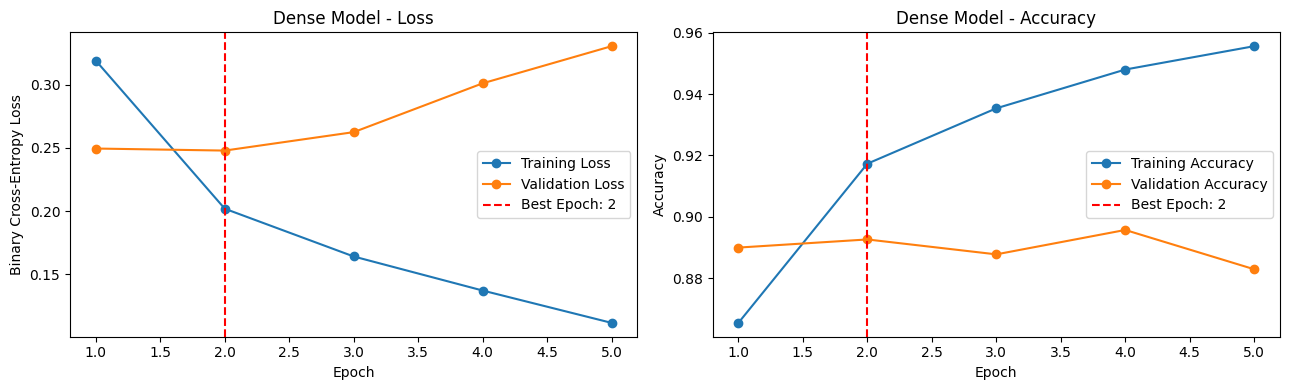

Best Epoch: 2
Best Validation Loss: 0.2479


In [30]:
# Convert training history into a DataFrame
history_df = pd.DataFrame(history_1.history)

# Create epoch numbers
epochs = np.arange(1,len(history_df)+1)

# Find the best epoch
best_epoch = history_df["val_loss"].idxmin()+1

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Loss visualization
axes[0].plot(
    epochs,
    history_df["loss"],
    marker="o",
    label="Training Loss"
)

axes[0].plot(
    epochs,
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

axes[0].axvline(
    best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

axes[0].set_title("Dense Model - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()

# Accuracy visualization
axes[1].plot(
    epochs,
    history_df["accuracy"],
    marker="o",
    label="Training Accuracy"
)

axes[1].plot(
    epochs,
    history_df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

axes[1].axvline(
    best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

axes[1].set_title("Dense Model - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Best Epoch: {best_epoch}")
print(f"Best Validation Loss: {history_df['val_loss'].min():.4f}")

#### Key Findings: Dense Model Training

Our first Dense Neural Network contains
2,205,313 trainable parameters.

Training stopped after 5 epochs because
validation loss did not improve.

The lowest validation loss was 0.2469
at epoch 2.

After epoch 2, training loss continued to decrease,
but validation loss started to increase.

This suggests that the model was overfitting.

EarlyStopping restored the weights from
the best epoch.

Next, we will evaluate the model using
Macro F1-score and class-specific metrics.

### 5.7. Dense Neural Network Evaluation

We will evaluate our trained Dense Neural Network
using the validation dataset.

The model produces a probability between 0 and 1
for each customer review.

We will use a classification threshold of 0.50
for our first evaluation.

We will calculate:

- Accuracy
- Precision and Recall
- F1-score for each class
- Macro F1-score
- Confusion Matrix

We will compare these results with our optimized
Logistic Regression baseline.

The test dataset will remain unused.

In [31]:
# Predict probabilities on validation data
dense_val_prob = model_1.predict(X_val_dl, batch_size=32, verbose=0).ravel()

# Convert probabilities into class predictions
dense_val_pred = (dense_val_prob >= 0.50).astype(int)

# Calculate evaluation metrics
dense_accuracy = accuracy_score(
    y_val_dl,
    dense_val_pred
)

dense_macro_f1 = f1_score(
    y_val_dl,
    dense_val_pred,
    average="macro"
)

print(f"Validation Accuracy: {dense_accuracy:.4f}")
print(f"Validation Macro F1: {dense_macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_val_dl,
        dense_val_pred,
        labels=[0, 1],
        target_names=[
            "Not Recommended",
            "Recommended"
        ],
        digits=4,
        zero_division=0
    )
)

Validation Accuracy: 0.8926
Validation Macro F1: 0.8202

Classification Report:
                 precision    recall  f1-score   support

Not Recommended     0.7002    0.7122    0.7062       410
    Recommended     0.9361    0.9325    0.9343      1853

       accuracy                         0.8926      2263
      macro avg     0.8182    0.8224    0.8202      2263
   weighted avg     0.8933    0.8926    0.8930      2263



### 5.8. Confusion Matrix Analysis

The confusion matrix shows how many reviews
were correctly and incorrectly classified.

Our dataset contains more recommended reviews
than not recommended reviews.

For this reason, we need to examine the
performance of both classes separately.

We will focus on how many not recommended
reviews the model incorrectly predicts as recommended.

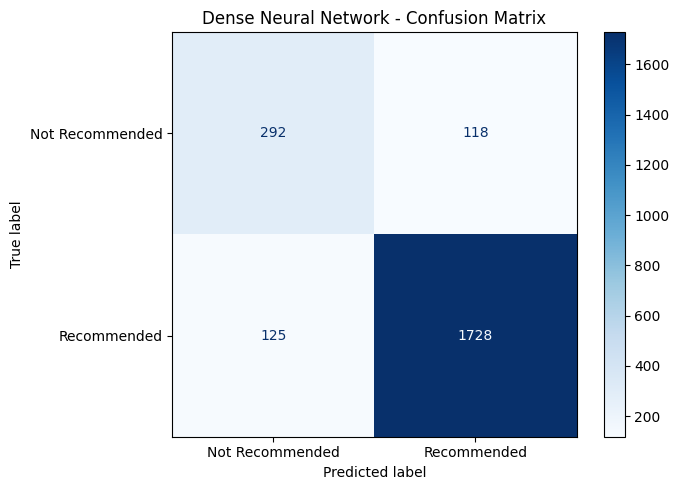

In [33]:
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val_dl,
    dense_val_pred,
    labels=[0, 1],
    display_labels=[
        "Not Recommended",
        "Recommended"
    ],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("Dense Neural Network - Confusion Matrix")

plt.tight_layout()
plt.show()

#### Key Findings: Dense Model Evaluation

Our Dense Neural Network achieved the following
results on the validation dataset:

- Accuracy: 89.26%
- Macro F1-score: 82.02%
- Not Recommended Recall: 71.22%
- Not Recommended F1-score: 70.62%

The model correctly classified 292 out of
410 not recommended reviews.

However, it incorrectly classified 118 not
recommended reviews as recommended.

The Dense model performed slightly worse than
our optimized Logistic Regression baseline.

We will test different classification thresholds
to improve the model's performance.

### 5.9. Dense Model Threshold Optimization

Our Dense Neural Network uses a default
classification threshold of 0.50.

However, this may not be the best threshold
for our imbalanced dataset.

We will test different threshold values
using the validation dataset.

Our main evaluation metric is Macro F1-score.

We will also examine minority-class
precision and recall.

The goal is to find a better balance between
the two recommendation classes.

We will not retrain the model or use
the test dataset in this step.

In [35]:
# Define threshold values
dense_thresholds = np.round(np.arange(0.20, 0.801, 0.025), 3)

dense_threshold_results = []

for threshold in dense_thresholds:

    # Convert probabilities to class predictions
    y_pred =(dense_val_prob >= threshold).astype(int)

    # Calculate evaluation metrics
    dense_threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_val_dl, y_pred),
        "macro_f1": f1_score(
            y_val_dl,
            y_pred,
            average="macro"
        ),
        "class_0_precision": precision_score(
            y_val_dl,
            y_pred,
            pos_label=0,
            zero_division=0
        ),
        "class_0_recall": recall_score(
            y_val_dl,
            y_pred,
            pos_label=0,
            zero_division=0
        )
    })

# Create results DataFrame
dense_threshold_results = pd.DataFrame(
    dense_threshold_results
)

# Select the best threshold
best_dense_idx = dense_threshold_results[
    "macro_f1"
].idxmax()

best_dense_threshold = float(
    dense_threshold_results.loc[
        best_dense_idx, "threshold"
    ]
)

best_dense_macro_f1 = float(
    dense_threshold_results.loc[
        best_dense_idx, "macro_f1"
    ]
)

# Display the best thresholds
display(
    dense_threshold_results
    .sort_values("macro_f1", ascending=False)
    .head(10)
    .round(4)
)

print(f"Best Threshold: {best_dense_threshold:.3f}")
print(f"Best Macro F1: {best_dense_macro_f1:.4f}")

,threshold,accuracy,macro_f1,class_0_precision,class_0_recall
16,0.60,0.89,0.82,0.67,0.77
18,0.65,0.89,0.82,0.65,0.80
15,0.57,0.89,0.82,0.68,0.76
14,0.55,0.89,0.82,0.68,0.75
10,0.45,0.90,0.82,0.73,0.69
13,0.53,0.89,0.82,0.69,0.73
9,0.42,0.90,0.82,0.74,0.68
11,0.47,0.89,0.82,0.71,0.70
17,0.62,0.89,0.82,0.66,0.78
8,0.40,0.90,0.82,0.74,0.67


Best Threshold: 0.600
Best Macro F1: 0.8248


#### Key Findings: Dense Threshold Optimization

We tested different classification thresholds
for our Dense Neural Network.

The best validation Macro F1-score was 0.8248
with a threshold of 0.60.

This improved the original Macro F1-score of 0.8202.

However, our optimized Logistic Regression model
still performs slightly better with a score of 0.8303.

The Dense model will remain part of our
model comparison experiments.

Next, we will train an LSTM model to learn
patterns from word sequences.

### 5.10. Building an LSTM Model

Our previous Dense model used average word embeddings.

This approach is simple and efficient, but it does
not directly preserve word order.

LSTM is a type of Recurrent Neural Network (RNN).

It processes words in sequence and uses memory
to learn information from previous words.

In this experiment, we will:

- Reuse our training vocabulary.
- Create a new Embedding layer.
- Add an LSTM layer with 64 units.
- Use Dropout to reduce overfitting.
- Predict recommendation probabilities.

We will compare the LSTM model with our previous
models using the same validation dataset.

In [36]:
# Define input layer
inputs = layers.Input(
    shape=(1,),
    dtype=tf.string,
    name="review_text"
)

# Text vectorization
x = text_vectorizer(inputs)

# Embedding layer
x = layers.Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    mask_zero=True,
    name="embedding"
)(x)

# LSTM layer
x = layers.LSTM(
    units=64,
    # Returns only the final output vector
    return_sequences=False,
    dropout=0.0,
    # Dropout is not applied to recurrent connections.
    recurrent_dropout=0.0,
)(x)

# Regularization
x = layers.Dropout(0.3)(x)

# Dense hidden layer
x = layers.Dense(
    32,
    activation="relu",
    name="dense_hidden"
)(x)

# Output layer
outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="output"
)(x)

# Build model
model_2 = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="lstm_nlp_model"
)

# Compile model
model_2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_2.summary()

Model: "lstm_nlp_model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 review_text (InputLayer)    [(None, 1)]               0         
                                                                 
 text_vectorization (TextVec  (None, 120)              0         
 torization)                                                     
                                                                 
 embedding (Embedding)       (None, 120, 128)          2196992   
                                                                 
 lstm (LSTM)                 (None, 64)                49408     
                                                                 
 dropout_1 (Dropout)         (None, 64)                0         
                                                                 
 dense_hidden (Dense)        (None, 32)                2080      
                                                    

### 5.11. Training the LSTM Model

We will train the LSTM model using our
normalized training reviews.

We will use the same training and validation
datasets as the Dense model.

EarlyStopping will monitor validation loss.

If validation loss does not improve for three
epochs, training will stop.

We will restore the best model weights.

We will first train the model without
class weights or threshold optimization.

In [37]:
# Create a new EarlyStopping callback
lstm_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Check available GPU
print(
    "Available GPUs:",
    tf.config.list_physical_devices("GPU")
)

# Train LSTM model
history_2 = model_2.fit(
    X_train_dl,
    y_train_dl,
    validation_data=(
        X_val_dl,
        y_val_dl
    ),
    epochs=15,
    batch_size=32,
    callbacks=[lstm_early_stopping],
    verbose=1
)

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Epoch 1/15
566/566 [==============================] - 13s 16ms/step - loss: 0.3147 - accuracy: 0.8677 - val_loss: 0.2585 - val_accuracy: 0.8909
Epoch 2/15
566/566 [==============================] - 8s 14ms/step - loss: 0.2070 - accuracy: 0.9147 - val_loss: 0.2737 - val_accuracy: 0.8917
Epoch 3/15
566/566 [==============================] - 8s 13ms/step - loss: 0.1540 - accuracy: 0.9404 - val_loss: 0.3070 - val_accuracy: 0.8710
Epoch 4/15
566/566 [==============================] - 8s 14ms/step - loss: 0.1119 - accuracy: 0.9575 - val_loss: 0.3331 - val_accuracy: 0.8851


### 5.12. LSTM Training History

We will analyze the training history of our LSTM model.

Our goals are to:

- Compare training and validation loss.
- Compare training and validation accuracy.
- Identify the best training epoch.
- Check whether the model shows signs of overfitting.

We will create a reusable visualization function.

This function will also be useful for our future
GRU, BiLSTM, and Conv1D models.

In [38]:
def plot_training_history(history, model_name):
    """
    Visualize training and validation metrics.

    Parameters
    ----------
    history : keras.callbacks.History
        Training history returned by model.fit().

    model_name : str
        Name of the trained model.
    """

    history_df = pd.DataFrame(history.history)

    epochs = np.arange(1, len(history_df) + 1)

    best_epoch = history_df["val_loss"].idxmin() + 1

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    # Loss plot
    axes[0].plot(
        epochs,
        history_df["loss"],
        marker="o",
        label="Training Loss"
    )

    axes[0].plot(
        epochs,
        history_df["val_loss"],
        marker="o",
        label="Validation Loss"
    )

    axes[0].set_title(f"{model_name} - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Binary Cross-Entropy Loss")

    # Accuracy plot
    axes[1].plot(
        epochs,
        history_df["accuracy"],
        marker="o",
        label="Training Accuracy"
    )

    axes[1].plot(
        epochs,
        history_df["val_accuracy"],
        marker="o",
        label="Validation Accuracy"
    )

    axes[1].set_title(f"{model_name} - Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")

    # Mark best epoch
    for ax in axes:
        ax.axvline(
            best_epoch,
            color="red",
            linestyle="--",
            label=f"Best Epoch: {best_epoch}"
        )
        ax.legend()
        ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

    print(f"Best Epoch: {best_epoch}")
    print(
        f"Best Validation Loss: "
        f"{history_df['val_loss'].min():.4f}"
    )

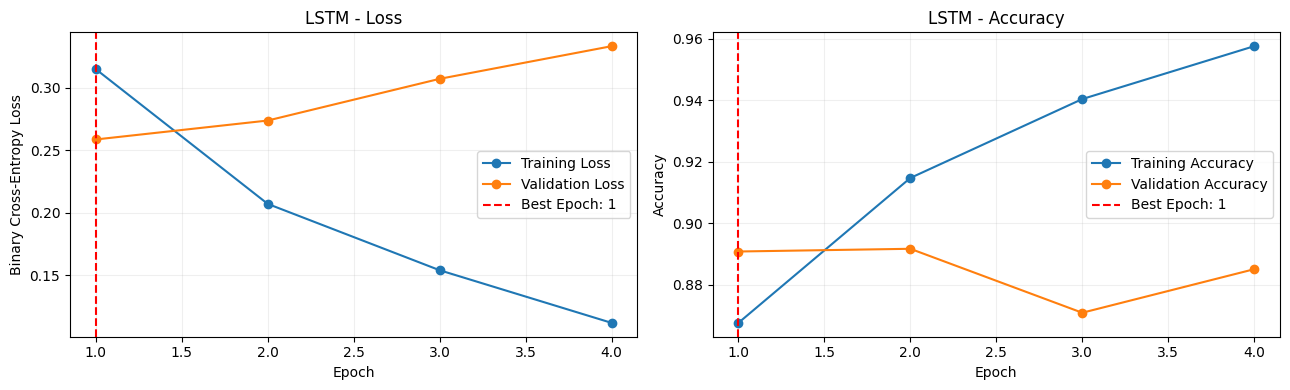

Best Epoch: 1
Best Validation Loss: 0.2585


In [39]:
plot_training_history(
    history=history_2,
    model_name="LSTM"
)

#### Key Findings: LSTM Training

The LSTM model contains 2,248,513 trainable parameters.

Training stopped after 4 epochs because
validation loss did not improve.

The lowest validation loss was 0.2585
at epoch 1.

Training accuracy increased during training,
but validation loss continued to increase.

This suggests that the model started to overfit
after the first epoch.

EarlyStopping restored the model weights
from the first epoch.

Next, we will evaluate the LSTM model using
Macro F1-score and class-specific metrics.

### 5.13. LSTM Model Evaluation

After training our LSTM model, we will evaluate
its performance on the validation dataset.

We will use the following metrics:

- Accuracy
- Precision
- Recall
- F1-score
- Macro F1-score

We will first use the default classification
threshold of 0.50.

Our main goal is to evaluate how well the LSTM
model identifies both recommendation classes.

We will compare its results with the Dense model
and Logistic Regression baseline.

The test dataset will remain unused.

In [40]:
# Predict validation probabilities
lstm_val_prob = model_2.predict(
    X_val_dl,
    batch_size=32,
    verbose=0
).ravel()

# Convert probabilities into class predictions
lstm_val_pred = (
    lstm_val_prob >= 0.50
).astype(int)

# Calculate evaluation metrics
lstm_accuracy = accuracy_score(
    y_val_dl,
    lstm_val_pred
)

lstm_macro_f1 = f1_score(
    y_val_dl,
    lstm_val_pred,
    average="macro"
)

# Display results
print(f"Validation Accuracy: {lstm_accuracy:.4f}")
print(f"Validation Macro F1: {lstm_macro_f1:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_val_dl,
        lstm_val_pred,
        labels=[0, 1],
        target_names=[
            "Not Recommended",
            "Recommended"
        ],
        digits=4,
        zero_division=0
    )
)

Validation Accuracy: 0.8909
Validation Macro F1: 0.8097

Classification Report:
                 precision    recall  f1-score   support

Not Recommended     0.7173    0.6561    0.6854       410
    Recommended     0.9253    0.9428    0.9340      1853

       accuracy                         0.8909      2263
      macro avg     0.8213    0.7994    0.8097      2263
   weighted avg     0.8876    0.8909    0.8889      2263



### 5.14. LSTM Confusion Matrix

We will use a confusion matrix to analyze
the predictions of our LSTM model.

The matrix will show:

- Correctly classified not recommended reviews.
- Incorrectly classified not recommended reviews.
- Correctly classified recommended reviews.
- Incorrectly classified recommended reviews.

This analysis will help us understand
the types of errors made by the model.

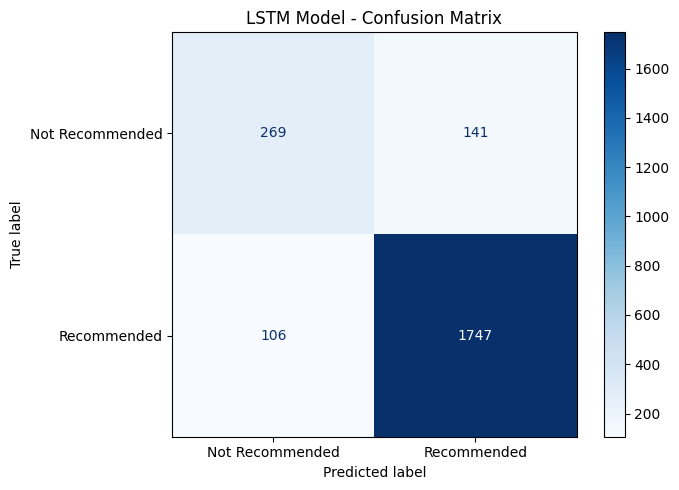

In [41]:
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val_dl,
    lstm_val_pred,
    labels=[0, 1],
    display_labels=[
        "Not Recommended",
        "Recommended"
    ],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("LSTM Model - Confusion Matrix")

plt.tight_layout()
plt.show()

#### Key Findings: LSTM Model Evaluation

Our LSTM model achieved the following results:

- Validation accuracy: 89.09%
- Macro F1-score: 80.97%
- Not Recommended Recall: 65.61%
- Not Recommended F1-score: 68.54%

The model correctly identified 269 out of 410
not recommended reviews.

However, it incorrectly classified 141 not
recommended reviews as recommended.

The LSTM model performed slightly worse than
our Dense model and Logistic Regression baseline.

This shows that a more complex model does not
always provide better results.

Next, we will optimize the classification threshold.

### 5.15. LSTM Threshold Optimization

Our LSTM model uses a default classification
threshold of 0.50.

However, this threshold may not provide the
best performance for our imbalanced dataset.

In this section, we will:

- Test different classification thresholds.
- Calculate Macro F1-score for each threshold.
- Compare minority-class precision and recall.
- Select the threshold with the highest Macro F1-score.

We will use only the validation dataset.

The model weights will remain unchanged.

In [42]:
# Define threshold values
lstm_thresholds = np.round(
    np.arange(0.20, 0.801, 0.025),
    3
)

lstm_threshold_results = []

for threshold in lstm_thresholds:

    # Convert probabilities to predictions
    y_pred = (
        lstm_val_prob >= threshold
    ).astype(int)

    # Calculate evaluation metrics
    lstm_threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(
            y_val_dl, y_pred
        ),
        "macro_f1": f1_score(
            y_val_dl,
            y_pred,
            average="macro"
        ),
        "class_0_precision": precision_score(
            y_val_dl,
            y_pred,
            pos_label=0,
            zero_division=0
        ),
        "class_0_recall": recall_score(
            y_val_dl,
            y_pred,
            pos_label=0,
            zero_division=0
        )
    })

# Create results DataFrame
lstm_threshold_results = pd.DataFrame(
    lstm_threshold_results
)

# Select best threshold
best_lstm_idx = lstm_threshold_results[
    "macro_f1"
].idxmax()

best_lstm_threshold = float(
    lstm_threshold_results.loc[
        best_lstm_idx, "threshold"
    ]
)

best_lstm_macro_f1 = float(
    lstm_threshold_results.loc[
        best_lstm_idx, "macro_f1"
    ]
)

# Display best results
display(
    lstm_threshold_results
    .sort_values("macro_f1", ascending=False)
    .head(10)
    .round(4)
)

print(f"Best Threshold: {best_lstm_threshold:.3f}")
print(f"Best Macro F1: {best_lstm_macro_f1:.4f}")

,threshold,accuracy,macro_f1,class_0_precision,class_0_recall
16,0.60,0.89,0.82,0.69,0.74
18,0.65,0.89,0.82,0.67,0.77
17,0.62,0.89,0.82,0.68,0.75
15,0.57,0.89,0.82,0.69,0.72
19,0.68,0.88,0.82,0.65,0.78
14,0.55,0.89,0.82,0.70,0.70
20,0.70,0.88,0.82,0.64,0.79
13,0.53,0.89,0.82,0.71,0.68
21,0.72,0.88,0.81,0.62,0.80
12,0.50,0.89,0.81,0.72,0.66


Best Threshold: 0.600
Best Macro F1: 0.8233


#### Key Findings: LSTM Threshold Optimization

We tested different classification thresholds
using the validation dataset.

The best results were:

- Best threshold: 0.60
- Optimized Macro F1-score: 0.8233
- Previous Macro F1-score: 0.8097
- Not Recommended Recall: approximately 74%

Threshold optimization improved the LSTM model.

However, the optimized Logistic Regression model
still achieved a higher Macro F1-score of 0.8303.

The LSTM and Dense models have similar performance.

Next, we will build a GRU model and compare
its results with our previous models.

### 5.16. Building a GRU Model

GRU stands for Gated Recurrent Unit.

It is a type of Recurrent Neural Network (RNN)
that processes sequential data.

Like LSTM, GRU can learn information from
previous words in a sentence.

However, GRU has a simpler structure and
usually uses fewer parameters than LSTM.

A GRU uses two main gates:

- Update Gate: Controls how much past information is kept.
- Reset Gate: Controls how past information is used.

In this experiment, we will build a GRU model
with 64 units.

We will compare its training behavior and
classification performance with the LSTM model.

In [43]:
# Set random seed
tf.random.set_seed(RANDOM_STATE)

# Input layer
inputs = layers.Input(
    shape=(1,),
    dtype=tf.string,
    name="review_text"
)

# Text vectorization
x = text_vectorizer(inputs)

# Embedding layer
x = layers.Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    mask_zero=True,
    name="embedding"
)(x)

# GRU layer
x = layers.GRU(
    units=64,
    return_sequences=False,
    dropout=0.0,
    recurrent_dropout=0.0,
    name="gru"
)(x)

# Regularization
x = layers.Dropout(0.3)(x)

# Dense hidden layer
x = layers.Dense(
    32,
    activation="relu",
    name="dense_hidden"
)(x)

# Output layer
outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="output"
)(x)

# Build GRU model
model_3 = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="gru_nlp_model"
)

# Compile model
model_3.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_3.summary()

Model: "gru_nlp_model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 review_text (InputLayer)    [(None, 1)]               0         
                                                                 
 text_vectorization (TextVec  (None, 120)              0         
 torization)                                                     
                                                                 
 embedding (Embedding)       (None, 120, 128)          2196992   
                                                                 
 gru (GRU)                   (None, 64)                37248     
                                                                 
 dropout_2 (Dropout)         (None, 64)                0         
                                                                 
 dense_hidden (Dense)        (None, 32)                2080      
                                                     

### 5.17. Training the GRU Model

We will train the GRU model using the same
training and validation datasets.

The training configuration will be similar
to our previous LSTM experiment.

We will use:

- Adam optimizer.
- Binary Cross-Entropy loss.
- Batch size of 32.
- Maximum of 15 epochs.
- EarlyStopping with patience of 3.

We will monitor validation loss to check
whether the model starts to overfit.

The test dataset will remain unused.

In [44]:
# Create EarlyStopping callback
gru_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Check available GPU
print(
    "Available GPUs:",
    tf.config.list_physical_devices("GPU")
)

# Train GRU model
history_3 = model_3.fit(
    X_train_dl,
    y_train_dl,
    validation_data=(
        X_val_dl,
        y_val_dl
    ),
    epochs=15,
    batch_size=32,
    callbacks=[gru_early_stopping],
    verbose=1
)

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Epoch 1/15
566/566 [==============================] - 11s 15ms/step - loss: 0.3232 - accuracy: 0.8633 - val_loss: 0.2735 - val_accuracy: 0.8847
Epoch 2/15
566/566 [==============================] - 7s 13ms/step - loss: 0.2054 - accuracy: 0.9153 - val_loss: 0.2880 - val_accuracy: 0.8878
Epoch 3/15
566/566 [==============================] - 7s 13ms/step - loss: 0.1506 - accuracy: 0.9407 - val_loss: 0.3256 - val_accuracy: 0.8670
Epoch 4/15
566/566 [==============================] - 7s 13ms/step - loss: 0.1095 - accuracy: 0.9592 - val_loss: 0.3420 - val_accuracy: 0.8794


#### Key Findings: GRU Training

Our GRU model contains 2,236,353 trainable parameters.

The GRU layer uses fewer parameters than
the LSTM layer.

The best validation loss was 0.2735 at epoch 1.

Training accuracy increased during training,
but validation loss continued to increase.

This suggests that the model started to overfit
after the first epoch.

EarlyStopping stopped training after 4 epochs
and restored the best model weights.

The GRU model achieved a higher validation loss
than our previous Dense and LSTM models.

Next, we will visualize the training history
and evaluate its classification performance.

### 5.18. GRU Training History Visualization

We will visualize the training history of our GRU model.

We want to understand:

- How training loss changes over time.
- How validation loss changes over time.
- Whether training accuracy continues to increase.
- When the model starts to show signs of overfitting.

We will reuse the visualization function
created during our LSTM experiment.

This will help us compare the training behavior
of our deep learning models.

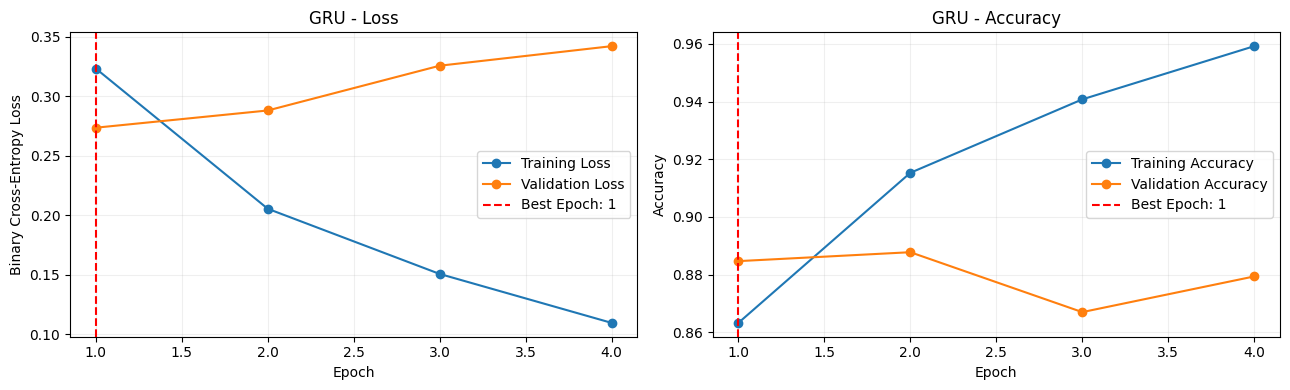

Best Epoch: 1
Best Validation Loss: 0.2735


In [45]:
# Visualize GRU training history
plot_training_history(
    history=history_3,
    model_name="GRU"
)

### 5.19. GRU Model Evaluation

After training our GRU model, we will evaluate
its performance on the validation dataset.

We will use the model weights restored by EarlyStopping.

First, we will use the default classification
threshold of 0.50.

We will calculate the following metrics:

- Accuracy
- Precision
- Recall
- F1-score
- Macro F1-score

Our main focus is Macro F1-score because
the dataset has an imbalanced class distribution.

We will also examine how well the model
identifies not recommended reviews.

The test dataset will remain unused.

In [46]:
# Predict validation probabilities
gru_val_prob = model_3.predict(
    X_val_dl,
    batch_size=32,
    verbose=0
).ravel()

# Convert probabilities into predictions
gru_val_pred = (
    gru_val_prob >= 0.50
).astype(int)

# Calculate evaluation metrics
gru_accuracy = accuracy_score(
    y_val_dl,
    gru_val_pred
)

gru_macro_f1 = f1_score(
    y_val_dl,
    gru_val_pred,
    average="macro"
)

# Display results
print(f"Validation Accuracy: {gru_accuracy:.4f}")
print(f"Validation Macro F1: {gru_macro_f1:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_val_dl,
        gru_val_pred,
        labels=[0, 1],
        target_names=[
            "Not Recommended",
            "Recommended"
        ],
        digits=4,
        zero_division=0
    )
)

Validation Accuracy: 0.8847
Validation Macro F1: 0.7943

Classification Report:
                 precision    recall  f1-score   support

Not Recommended     0.7110    0.6122    0.6579       410
    Recommended     0.9168    0.9450    0.9306      1853

       accuracy                         0.8847      2263
      macro avg     0.8139    0.7786    0.7943      2263
   weighted avg     0.8795    0.8847    0.8812      2263



### 5.20. GRU Confusion Matrix

We will use a confusion matrix to understand
the classification errors of our GRU model.

The matrix shows the number of correct
and incorrect predictions for each class.

We are especially interested in reviews
that belong to the Not Recommended class
but are predicted as Recommended.

This analysis will help us compare the GRU
model with our previous deep learning models.

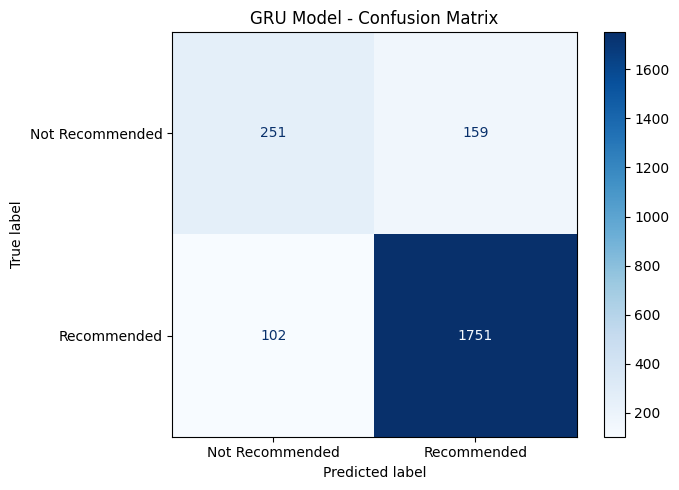

In [47]:
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val_dl,
    gru_val_pred,
    labels=[0, 1],
    display_labels=[
        "Not Recommended",
        "Recommended"
    ],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("GRU Model - Confusion Matrix")

plt.tight_layout()
plt.show()

#### Key Findings: GRU Model Evaluation

Our GRU model achieved the following validation results:

- Accuracy: 88.47%
- Macro F1-score: 79.43%
- Not Recommended Recall: 61.22%
- Not Recommended F1-score: 65.79%

The model correctly identified 251 out of
410 not recommended reviews.

However, it incorrectly classified 159
not recommended reviews as recommended.

The GRU model performed worse than our Dense
and LSTM models at the default threshold.

Next, we will optimize the classification
threshold to improve Macro F1-score.

### 5.21. GRU Threshold Optimization

Our GRU model uses a default classification
threshold of 0.50.

However, this threshold may not provide
the best performance for our dataset.

We will test different threshold values
using the validation dataset.

For each threshold, we will calculate:

- Accuracy
- Macro F1-score
- Not Recommended Precision
- Not Recommended Recall

We will select the threshold with the
highest validation Macro F1-score.

The model weights will remain unchanged.
The test dataset will not be used.

In [48]:
# Define classification thresholds
gru_thresholds = np.round(
    np.arange(0.20, 0.801, 0.025),
    3
)

gru_threshold_results = []

for threshold in gru_thresholds:

    # Convert probabilities into predictions
    y_pred = (
        gru_val_prob >= threshold
    ).astype(int)

    # Calculate evaluation metrics
    gru_threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(
            y_val_dl, y_pred
        ),
        "macro_f1": f1_score(
            y_val_dl,
            y_pred,
            average="macro"
        ),
        "class_0_precision": precision_score(
            y_val_dl,
            y_pred,
            pos_label=0,
            zero_division=0
        ),
        "class_0_recall": recall_score(
            y_val_dl,
            y_pred,
            pos_label=0,
            zero_division=0
        )
    })

# Convert results into DataFrame
gru_threshold_results = pd.DataFrame(
    gru_threshold_results
)

# Find the best threshold
best_gru_idx = gru_threshold_results[
    "macro_f1"
].idxmax()

best_gru_threshold = float(
    gru_threshold_results.loc[
        best_gru_idx, "threshold"
    ]
)

best_gru_macro_f1 = float(
    gru_threshold_results.loc[
        best_gru_idx, "macro_f1"
    ]
)

# Display top 10 thresholds
display(
    gru_threshold_results
    .sort_values("macro_f1", ascending=False)
    .head(10)
    .round(4)
)

print(f"Best Threshold: {best_gru_threshold:.3f}")
print(f"Best Macro F1: {best_gru_macro_f1:.4f}")

,threshold,accuracy,macro_f1,class_0_precision,class_0_recall
21,0.72,0.88,0.81,0.66,0.75
23,0.78,0.88,0.81,0.64,0.78
20,0.70,0.88,0.81,0.66,0.74
22,0.75,0.88,0.81,0.65,0.76
24,0.80,0.88,0.81,0.63,0.79
19,0.68,0.88,0.81,0.67,0.71
17,0.62,0.89,0.81,0.69,0.69
18,0.65,0.89,0.81,0.68,0.70
16,0.60,0.89,0.81,0.69,0.67
15,0.57,0.89,0.80,0.70,0.66


Best Threshold: 0.725
Best Macro F1: 0.8138


#### Key Findings: GRU Threshold Optimization

We tested different classification thresholds
using the validation dataset.

The best results were:

- Best threshold: 0.725
- Optimized Macro F1-score: 0.8138
- Previous Macro F1-score: 0.7943

Threshold optimization improved the GRU model.

However, GRU still performed worse than our
Logistic Regression, Dense, and LSTM models.

This suggests that a more complex neural network
does not always provide better classification results.

Next, we will build a Bidirectional LSTM model.

### 5.22. Building a Bidirectional LSTM Model

Bidirectional LSTM (BiLSTM) is an extension of LSTM.

A standard LSTM processes text in one direction.

BiLSTM uses two LSTM networks:

- Forward LSTM processes words from left to right.
- Backward LSTM processes words from right to left.

The model combines information from both directions.

This can help the model learn relationships
between words in different parts of a sentence.

In this experiment, we will:

- Use the same training vocabulary.
- Create a new Embedding layer.
- Build a Bidirectional LSTM with 64 units per direction.
- Apply Dropout to reduce overfitting.
- Evaluate the model on the validation dataset.

We will compare BiLSTM with our previous models.

In [49]:
# Set random seed
tf.random.set_seed(RANDOM_STATE)

# Input layer
inputs = layers.Input(
    shape=(1,),
    dtype=tf.string,
    name="review_text"
)

# Text vectorization
x = text_vectorizer(inputs)

# Embedding layer
x = layers.Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    mask_zero=True,
    name="embedding"
)(x)

# Bidirectional LSTM
x = layers.Bidirectional(
    layers.LSTM(
        units=64,
        return_sequences=False,
        dropout=0.0,
        recurrent_dropout=0.0
    ),
    name="bidirectional_lstm"
)(x)

# Dropout
x = layers.Dropout(0.3)(x)

# Dense hidden layer
x = layers.Dense(
    32,
    activation="relu",
    name="dense_hidden"
)(x)

# Output layer
outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="output"
)(x)

# Build model
model_4 = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="bilstm_nlp_model"
)

# Compile model
model_4.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_4.summary()

Model: "bilstm_nlp_model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 review_text (InputLayer)    [(None, 1)]               0         
                                                                 
 text_vectorization (TextVec  (None, 120)              0         
 torization)                                                     
                                                                 
 embedding (Embedding)       (None, 120, 128)          2196992   
                                                                 
 bidirectional_lstm (Bidirec  (None, 128)              98816     
 tional)                                                         
                                                                 
 dropout_3 (Dropout)         (None, 128)               0         
                                                                 
 dense_hidden (Dense)        (None, 32)           

### 5.23. Training the Bidirectional LSTM Model

We will train our BiLSTM model using the
same training and validation datasets.

We will use the following settings:

- Adam optimizer with a learning rate of 0.001.
- Binary Cross-Entropy loss.
- Batch size of 32.
- Maximum of 15 epochs.
- EarlyStopping with patience of 3.

We will monitor validation loss during training.

EarlyStopping will restore the model weights
from the epoch with the lowest validation loss.

Our main goal is to understand whether processing
text in both directions improves model performance.

The test dataset will remain unused.

In [50]:
# EarlyStopping callback
bilstm_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Check GPU
print(
    "Available GPUs:",
    tf.config.list_physical_devices("GPU")
)

# Train BiLSTM model
history_4 = model_4.fit(
    X_train_dl,
    y_train_dl,
    validation_data=(
        X_val_dl,
        y_val_dl
    ),
    epochs=15,
    batch_size=32,
    callbacks=[bilstm_early_stopping],
    verbose=1
)

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Epoch 1/15
566/566 [==============================] - 19s 25ms/step - loss: 0.2885 - accuracy: 0.8768 - val_loss: 0.2489 - val_accuracy: 0.8900
Epoch 2/15
566/566 [==============================] - 12s 21ms/step - loss: 0.1816 - accuracy: 0.9254 - val_loss: 0.2709 - val_accuracy: 0.8917
Epoch 3/15
566/566 [==============================] - 12s 21ms/step - loss: 0.1263 - accuracy: 0.9503 - val_loss: 0.3184 - val_accuracy: 0.8741
Epoch 4/15
566/566 [==============================] - 12s 22ms/step - loss: 0.0846 - accuracy: 0.9668 - val_loss: 0.3357 - val_accuracy: 0.8802


### 5.24. BiLSTM Training History Visualization

We will examine the training history of our
Bidirectional LSTM model.

Our main goals are to:

- Compare training and validation loss.
- Compare training and validation accuracy.
- Identify the epoch with the lowest validation loss.
- Check whether the model shows signs of overfitting.

We will use the same visualization function
from our previous deep learning experiments.

This will help us compare the training behavior
of Dense, LSTM, GRU, and BiLSTM models.

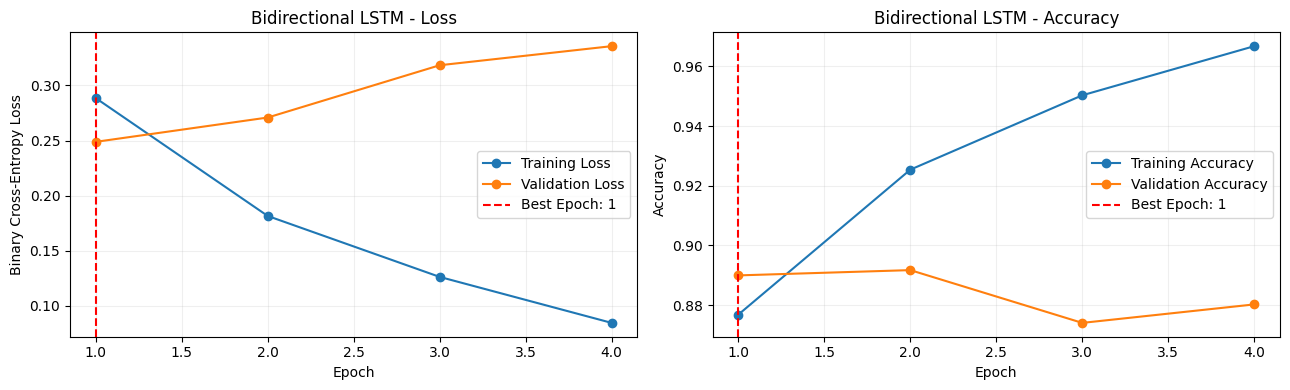

Best Epoch: 1
Best Validation Loss: 0.2489


In [51]:
# Visualize BiLSTM training history
plot_training_history(
    history=history_4,
    model_name="Bidirectional LSTM"
)

#### Key Findings: BiLSTM Training

Our Bidirectional LSTM model contains
2,299,969 trainable parameters.

Training stopped after 4 epochs.

The lowest validation loss was 0.2489
at epoch 1.

Training accuracy increased from 87.68%
to 96.68%.

However, validation loss increased after
the first epoch.

This suggests that the model started to overfit.

BiLSTM achieved a lower validation loss
than our LSTM and GRU models.

However, the Dense model still has the
lowest validation loss.

Next, we will evaluate the BiLSTM model
using classification metrics.

### 5.25. BiLSTM Model Evaluation

After training our Bidirectional LSTM model,
we will evaluate its classification performance.

We will use the validation dataset and the
best model weights restored by EarlyStopping.

First, we will use the default classification
threshold of 0.50.

We will calculate:

- Accuracy
- Precision
- Recall
- F1-score
- Macro F1-score

Our main evaluation metric is Macro F1-score
because the dataset has imbalanced classes.

We will also examine how well the model
identifies not recommended reviews.

The test dataset will remain unused.

In [52]:
# Predict validation probabilities
bilstm_val_prob = model_4.predict(
    X_val_dl,
    batch_size=32,
    verbose=0
).ravel()

# Convert probabilities into class predictions
bilstm_val_pred = (
    bilstm_val_prob >= 0.50
).astype(int)

# Calculate evaluation metrics
bilstm_accuracy = accuracy_score(
    y_val_dl,
    bilstm_val_pred
)

bilstm_macro_f1 = f1_score(
    y_val_dl,
    bilstm_val_pred,
    average="macro"
)

# Display results
print(f"Validation Accuracy: {bilstm_accuracy:.4f}")
print(f"Validation Macro F1: {bilstm_macro_f1:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_val_dl,
        bilstm_val_pred,
        labels=[0, 1],
        target_names=[
            "Not Recommended",
            "Recommended"
        ],
        digits=4,
        zero_division=0
    )
)

Validation Accuracy: 0.8900
Validation Macro F1: 0.7978

Classification Report:
                 precision    recall  f1-score   support

Not Recommended     0.7477    0.5927    0.6612       410
    Recommended     0.9138    0.9557    0.9343      1853

       accuracy                         0.8900      2263
      macro avg     0.8308    0.7742    0.7978      2263
   weighted avg     0.8837    0.8900    0.8848      2263



### 5.26. BiLSTM Confusion Matrix

The confusion matrix shows the number of correct
and incorrect predictions for each class.

We will examine how many customer reviews
the BiLSTM model classifies correctly.

We will focus on two types of errors:

- Not recommended reviews predicted as recommended.
- Recommended reviews predicted as not recommended.

This analysis will help us understand
the strengths and weaknesses of our BiLSTM model.

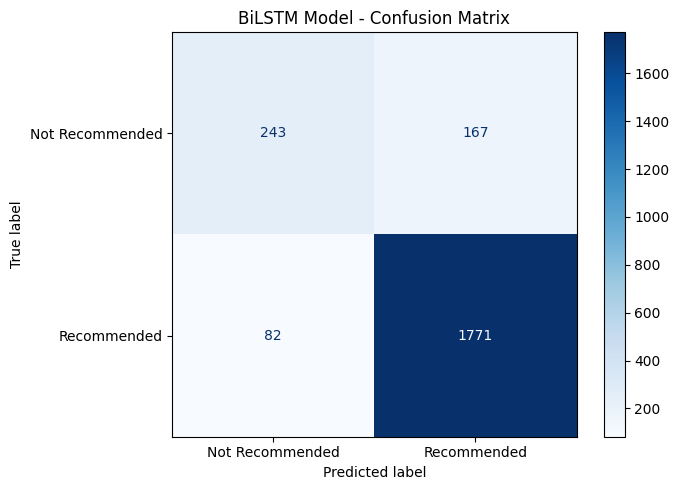

In [53]:
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val_dl,
    bilstm_val_pred,
    labels=[0, 1],
    display_labels=[
        "Not Recommended",
        "Recommended"
    ],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("BiLSTM Model - Confusion Matrix")

plt.tight_layout()
plt.show()

#### Key Findings: BiLSTM Model Evaluation

Our Bidirectional LSTM model achieved the following
results on the validation dataset:

- Accuracy: 89.00%
- Macro F1-score: 79.78%
- Not Recommended Precision: 74.77%
- Not Recommended Recall: 59.27%

The model correctly identified 243 out of
410 not recommended reviews.

However, it incorrectly classified 167 not
recommended reviews as recommended.

The model performed well on recommended reviews,
but it had difficulty identifying the minority class.

BiLSTM performed worse than the standard LSTM
model at the default threshold of 0.50.

Next, we will optimize the classification threshold.

### 5.27. BiLSTM Threshold Optimization

Our BiLSTM model currently uses a classification
threshold of 0.50.

This threshold may not provide the best results
for our imbalanced dataset.

We will test different thresholds using
the validation dataset.

For each threshold, we will calculate:

- Accuracy
- Macro F1-score
- Not Recommended Precision
- Not Recommended Recall

We will select the threshold with the highest
validation Macro F1-score.

We will also create a reusable function
for future model experiments.

The model weights will remain unchanged.

In [54]:
def evaluate_thresholds(y_true, y_prob):
    """
    Evaluate classification thresholds using
    validation probabilities.
    """

    thresholds = np.round(
        np.arange(0.20, 0.801, 0.025),
        3
    )

    results = []

    for threshold in thresholds:

        y_pred = (y_prob >= threshold).astype(int)

        results.append({
            "threshold": threshold,
            "accuracy": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(
                y_true, y_pred, average="macro"
            ),
            "class_0_precision": precision_score(
                y_true, y_pred,
                pos_label=0,
                zero_division=0
            ),
            "class_0_recall": recall_score(
                y_true, y_pred,
                pos_label=0,
                zero_division=0
            )
        })

    return pd.DataFrame(results)

In [55]:
# Evaluate BiLSTM thresholds
bilstm_threshold_results = evaluate_thresholds(
    y_true=y_val_dl,
    y_prob=bilstm_val_prob
)

# Find the best threshold
best_bilstm_idx = (
    bilstm_threshold_results["macro_f1"].idxmax()
)

best_bilstm_threshold = float(
    bilstm_threshold_results.loc[
        best_bilstm_idx, "threshold"
    ]
)

best_bilstm_macro_f1 = float(
    bilstm_threshold_results.loc[
        best_bilstm_idx, "macro_f1"
    ]
)

# Display the best 10 results
display(
    bilstm_threshold_results
    .sort_values("macro_f1", ascending=False)
    .head(10)
    .round(4)
)

print(f"Best Threshold: {best_bilstm_threshold:.3f}")
print(f"Best Macro F1: {best_bilstm_macro_f1:.4f}")

,threshold,accuracy,macro_f1,class_0_precision,class_0_recall
22,0.75,0.89,0.83,0.66,0.80
21,0.72,0.89,0.83,0.67,0.78
20,0.70,0.89,0.82,0.68,0.75
19,0.68,0.89,0.82,0.69,0.74
23,0.78,0.88,0.82,0.64,0.81
18,0.65,0.89,0.82,0.70,0.71
17,0.62,0.89,0.82,0.71,0.70
24,0.80,0.87,0.81,0.61,0.82
16,0.60,0.89,0.81,0.70,0.67
15,0.57,0.89,0.81,0.71,0.66


Best Threshold: 0.750
Best Macro F1: 0.8289


#### Key Findings: BiLSTM Threshold Optimization

Threshold optimization improved our BiLSTM model.

The best validation results were:

- Best threshold: 0.75
- Macro F1-score: 0.8289
- Previous Macro F1-score: 0.7978
- Not Recommended Recall: approximately 80%

The optimized BiLSTM model achieved better results
than our previous Dense, LSTM, and GRU models.

Its performance is now very close to our
Logistic Regression baseline.

These results show that classification thresholds
can have an important effect on model performance.

Next, we will develop our final deep learning
architecture using Conv1D.

### 5.28. Building a Conv1D Model

Conv1D stands for One-Dimensional Convolutional Layer.

It can learn local patterns from sequences of words.

Unlike LSTM and GRU, Conv1D uses filters that
move across the input sequence.

For example, a filter with a kernel size of 3
examines three consecutive tokens at a time.

Our model will include:

- TextVectorization to convert text into token IDs.
- Embedding to create trainable word vectors.
- Conv1D to learn local text patterns.
- GlobalMaxPooling1D to select important features.
- Dense and Dropout layers for classification.
- Sigmoid activation to predict recommendations.

We will compare this model with our previous
machine learning and deep learning models.

In [56]:
# Set random seed
tf.random.set_seed(RANDOM_STATE)

# Input layer
inputs = layers.Input(
    shape=(1,),
    dtype=tf.string,
    name="review_text"
)

# Text vectorization
x = text_vectorizer(inputs)

# Embedding layer
x = layers.Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    mask_zero=False,
    name="embedding"
)(x)

# Convolutional layer
x = layers.Conv1D(
    # The number of different local features to be learned
    filters=64,
    # Each filter examines the positions of three tokens simultaneously.
    kernel_size=3,
    # Learns non-linear relationships
    activation="relu",
    # It does not create additional padding before the convolution.
    padding="valid",
    name="conv1d"
)(x)

# Global Max Pooling
# It selects the highest activation for each filter produced by Conv1D.
# This allows the model to learn whether a strong pattern exists in any part of the comment.
x = layers.GlobalMaxPooling1D(
    name="global_max_pooling"
)(x)

# Dense hidden layer
x = layers.Dense(
    32,
    activation="relu",
    name="dense_hidden"
)(x)

# Dropout
x = layers.Dropout(0.3)(x)

# Output layer
outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="output"
)(x)

# Build model
model_5 = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="conv1d_nlp_model"
)

# Compile model
model_5.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_5.summary()

Model: "conv1d_nlp_model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 review_text (InputLayer)    [(None, 1)]               0         
                                                                 
 text_vectorization (TextVec  (None, 120)              0         
 torization)                                                     
                                                                 
 embedding (Embedding)       (None, 120, 128)          2196992   
                                                                 
 conv1d (Conv1D)             (None, 118, 64)           24640     
                                                                 
 global_max_pooling (GlobalM  (None, 64)               0         
 axPooling1D)                                                    
                                                                 
 dense_hidden (Dense)        (None, 32)           

### 5.29. Training the Conv1D Model

We will train our Conv1D model using
the same training and validation datasets.

We will use:

- Adam optimizer with a learning rate of 0.001.
- Binary Cross-Entropy loss.
- Batch size of 32.
- Maximum of 15 epochs.
- EarlyStopping with patience of 3.

We will monitor validation loss during training.

We want to understand whether Conv1D can learn
useful patterns from customer reviews.

We will also check whether the model
shows signs of overfitting.

The test dataset will remain unused.

In [57]:
# EarlyStopping callback
conv1d_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Check GPU
print(
    "Available GPUs:",
    tf.config.list_physical_devices("GPU")
)

# Train Conv1D model
history_5 = model_5.fit(
    X_train_dl,
    y_train_dl,
    validation_data=(
        X_val_dl,
        y_val_dl
    ),
    epochs=15,
    batch_size=32,
    callbacks=[conv1d_early_stopping],
    verbose=1
)

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Epoch 1/15
566/566 [==============================] - 6s 6ms/step - loss: 0.3359 - accuracy: 0.8573 - val_loss: 0.2650 - val_accuracy: 0.8816
Epoch 2/15
566/566 [==============================] - 3s 6ms/step - loss: 0.2011 - accuracy: 0.9189 - val_loss: 0.2530 - val_accuracy: 0.8917
Epoch 3/15
566/566 [==============================] - 3s 6ms/step - loss: 0.1226 - accuracy: 0.9541 - val_loss: 0.2657 - val_accuracy: 0.8944
Epoch 4/15
566/566 [==============================] - 3s 6ms/step - loss: 0.0649 - accuracy: 0.9788 - val_loss: 0.3417 - val_accuracy: 0.8931
Epoch 5/15
566/566 [==============================] - 3s 6ms/step - loss: 0.0296 - accuracy: 0.9916 - val_loss: 0.4195 - val_accuracy: 0.8900


#### Key Findings: Conv1D Training

Our Conv1D model contains 2,223,745 trainable parameters.

Training stopped after 5 epochs.

The lowest validation loss was 0.2530
at epoch 2.

Training accuracy increased to 99.16%,
while validation accuracy remained around 89%.

After epoch 2, validation loss increased
while training loss continued to decrease.

This shows clear signs of overfitting.

EarlyStopping restored the model weights
from the second epoch.

Next, we will visualize the training history
and evaluate classification performance.

### 5.30. Conv1D Training History Visualization

We will examine the training history of our
Conv1D model.

Our main goals are to:

- Compare training and validation loss.
- Compare training and validation accuracy.
- Identify the best epoch.
- Understand the signs of overfitting.

We will use the same visualization function
as our previous deep learning experiments.

This will help us compare training behavior
across different model architectures.

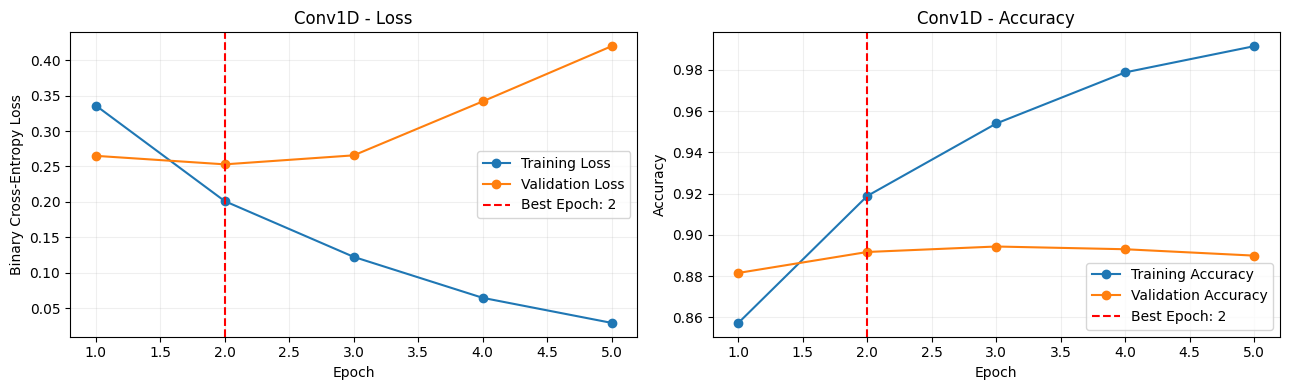

Best Epoch: 2
Best Validation Loss: 0.2530


In [58]:
# Visualize Conv1D training history
plot_training_history(
    history=history_5,
    model_name="Conv1D"
)

### 5.31. Conv1D Model Evaluation

After training our Conv1D model, we will evaluate
its performance on the validation dataset.

We will use the best model weights restored
by EarlyStopping.

First, we will use the default classification
threshold of 0.50.

We will calculate the following metrics:

- Accuracy
- Precision
- Recall
- F1-score
- Macro F1-score

Our main evaluation metric is Macro F1-score
because the dataset has an imbalanced target.

We will also examine how well the model
identifies not recommended reviews.

The test dataset will remain unused.

In [59]:
# Predict validation probabilities
conv1d_val_prob = model_5.predict(
    X_val_dl,
    batch_size=32,
    verbose=0
).ravel()

# Convert probabilities into class predictions
conv1d_val_pred = (
    conv1d_val_prob >= 0.50
).astype(int)

# Calculate evaluation metrics
conv1d_accuracy = accuracy_score(
    y_val_dl,
    conv1d_val_pred
)

conv1d_macro_f1 = f1_score(
    y_val_dl,
    conv1d_val_pred,
    average="macro"
)

# Display results
print(f"Validation Accuracy: {conv1d_accuracy:.4f}")
print(f"Validation Macro F1: {conv1d_macro_f1:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_val_dl,
        conv1d_val_pred,
        labels=[0, 1],
        target_names=[
            "Not Recommended",
            "Recommended"
        ],
        digits=4,
        zero_division=0
    )
)

Validation Accuracy: 0.8917
Validation Macro F1: 0.8211

Classification Report:
                 precision    recall  f1-score   support

Not Recommended     0.6914    0.7268    0.7087       410
    Recommended     0.9389    0.9282    0.9335      1853

       accuracy                         0.8917      2263
      macro avg     0.8151    0.8275    0.8211      2263
   weighted avg     0.8940    0.8917    0.8928      2263



### 5.32. Conv1D Confusion Matrix

We will use a confusion matrix to examine
the classification results of our Conv1D model.

The confusion matrix shows correct and
incorrect predictions for each target class.

We will focus on two important questions:

- How many not recommended reviews are correctly identified?
- How many not recommended reviews are predicted as recommended?

This analysis will help us understand
the strengths and weaknesses of the model.

We will also compare Conv1D with our previous
deep learning models.

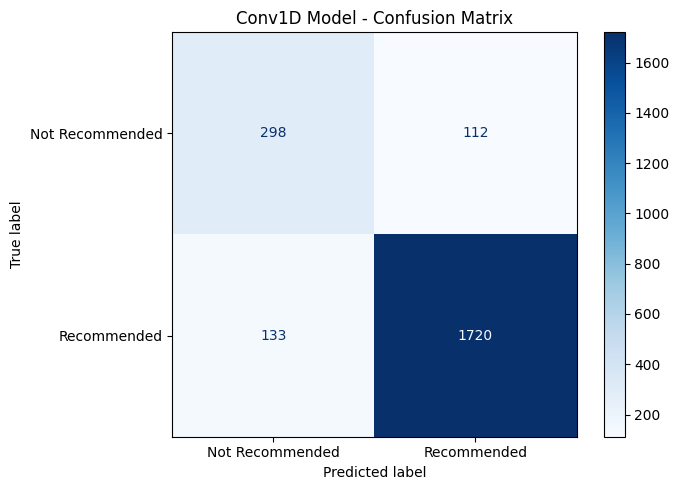

In [60]:
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val_dl,
    conv1d_val_pred,
    labels=[0, 1],
    display_labels=[
        "Not Recommended",
        "Recommended"
    ],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("Conv1D Model - Confusion Matrix")

plt.tight_layout()
plt.show()

#### Key Findings: Conv1D Model Evaluation

Our Conv1D model achieved the following results:

- Validation Accuracy: 89.17%
- Macro F1-score: 82.11%
- Not Recommended Recall: 72.68%
- Not Recommended F1-score: 70.87%

The model correctly identified 298 out of
410 not recommended reviews.

However, it incorrectly classified 112
not recommended reviews as recommended.

At the default threshold of 0.50, Conv1D
achieved the highest Macro F1-score among
our deep learning models.

The results are close to our Dense model.

Next, we will optimize the classification
threshold to improve the model's performance.

### 5.33. Conv1D Threshold Optimization

Our Conv1D model achieved a Macro F1-score
of 0.8211 with the default threshold of 0.50.

However, this threshold may not provide
the best classification performance.

We will test different threshold values
using the validation dataset.

For each threshold, we will calculate:

- Accuracy
- Macro F1-score
- Not Recommended Precision
- Not Recommended Recall

Our goal is to find the threshold that
maximizes validation Macro F1-score.

The model weights will remain unchanged.

We will not use the test dataset during
this optimization process.

In [61]:
# Evaluate Conv1D thresholds
conv1d_threshold_results = evaluate_thresholds(
    y_true=y_val_dl,
    y_prob=conv1d_val_prob
)

# Find the best threshold index
best_conv1d_idx = (
    conv1d_threshold_results["macro_f1"].idxmax()
)

# Extract the best threshold
best_conv1d_threshold = float(
    conv1d_threshold_results.loc[
        best_conv1d_idx, "threshold"
    ]
)

# Extract the best Macro F1-score
best_conv1d_macro_f1 = float(
    conv1d_threshold_results.loc[
        best_conv1d_idx, "macro_f1"
    ]
)

# Display the top 10 thresholds
display(
    conv1d_threshold_results
    .sort_values("macro_f1", ascending=False)
    .head(10)
    .round(4)
)

print(f"Best Threshold: {best_conv1d_threshold:.3f}")
print(f"Best Macro F1: {best_conv1d_macro_f1:.4f}")

,threshold,accuracy,macro_f1,class_0_precision,class_0_recall
13,0.53,0.89,0.82,0.68,0.74
14,0.55,0.89,0.82,0.67,0.75
12,0.50,0.89,0.82,0.69,0.73
11,0.47,0.89,0.82,0.70,0.71
18,0.65,0.88,0.82,0.64,0.80
15,0.57,0.89,0.82,0.66,0.76
19,0.68,0.88,0.82,0.63,0.81
17,0.62,0.88,0.82,0.64,0.78
16,0.60,0.88,0.81,0.65,0.76
10,0.45,0.89,0.81,0.71,0.68


Best Threshold: 0.525
Best Macro F1: 0.8228


#### Key Findings: Conv1D Threshold Optimization

We tested different classification thresholds
for our Conv1D model.

The best results were:

- Best threshold: 0.525
- Optimized Macro F1-score: 0.8228
- Previous Macro F1-score: 0.8211
- Not Recommended Recall: approximately 74%

Threshold optimization provided a small improvement.

However, the Conv1D model did not outperform
our best Logistic Regression model.

We have now completed our initial experiments
with five different deep learning architectures.

Next, we will compare all models and identify
the best candidates for further optimization.

## 6. Model Comparison and Optimization

### 6.1. Comparing Model Performance

We have trained six different classification models:

- Logistic Regression with TF-IDF
- Dense Neural Network
- LSTM
- GRU
- Bidirectional LSTM
- Conv1D

We also optimized the classification threshold
of each model using the validation dataset.

In this section, we will compare:

- Accuracy
- Macro F1-score
- Not Recommended Precision
- Not Recommended Recall
- Not Recommended F1-score

Our main evaluation metric is Macro F1-score.

We will use these results to select promising
models for further optimization.

The test dataset will remain unused until
the final model selection is complete.

In [62]:
# Store models and their validation predictions
model_predictions = {
    "Logistic Regression": (
        val_probabilities,
        best_threshold
    ),
    "Dense": (
        dense_val_prob,
        best_dense_threshold
    ),
    "LSTM": (
        lstm_val_prob,
        best_lstm_threshold
    ),
    "GRU": (
        gru_val_prob,
        best_gru_threshold
    ),
    "BiLSTM": (
        bilstm_val_prob,
        best_bilstm_threshold
    ),
    "Conv1D": (
        conv1d_val_prob,
        best_conv1d_threshold
    )
}

# Calculate validation metrics
comparison_results = []

for model_name, (probabilities, threshold) in model_predictions.items():

    predictions = (
        probabilities >= threshold
    ).astype(int)

    comparison_results.append({
        "model": model_name,
        "threshold": threshold,
        "accuracy": accuracy_score(
            y_val_dl, predictions
        ),
        "macro_f1": f1_score(
            y_val_dl,
            predictions,
            average="macro"
        ),
        "class_0_precision": precision_score(
            y_val_dl,
            predictions,
            pos_label=0,
            zero_division=0
        ),
        "class_0_recall": recall_score(
            y_val_dl,
            predictions,
            pos_label=0,
            zero_division=0
        ),
        "class_0_f1": f1_score(
            y_val_dl,
            predictions,
            pos_label=0,
            zero_division=0
        )
    })

# Create final comparison DataFrame
final_val_results = (
    pd.DataFrame(comparison_results)
    .sort_values(
        "macro_f1",
        ascending=False
    )
    .reset_index(drop=True)
)

display(final_val_results.round(4))

,model,threshold,accuracy,macro_f1,class_0_precision,class_0_recall,class_0_f1
0,Logistic Regression,0.40,0.90,0.83,0.69,0.76,0.73
1,BiLSTM,0.75,0.89,0.83,0.66,0.80,0.73
2,Dense,0.60,0.89,0.82,0.67,0.77,0.72
3,LSTM,0.60,0.89,0.82,0.69,0.74,0.71
4,Conv1D,0.53,0.89,0.82,0.68,0.74,0.71
5,GRU,0.72,0.88,0.81,0.66,0.75,0.70


#### Key Findings: Model Comparison

We compared six models using the validation dataset.

Our main findings are:

- Logistic Regression achieved the highest Macro F1-score.
- BiLSTM achieved a very similar Macro F1-score.
- BiLSTM identified more not recommended reviews.
- Dense, LSTM, and Conv1D showed competitive performance.
- All deep learning models showed signs of overfitting.

A more complex model did not always perform better.

We will now try to reduce overfitting by changing
the model capacity and regularization settings.

We will keep the test dataset separate until
the final evaluation.

### 6.2. Hyperparameter Optimization with Optuna

Hyperparameter tuning helps us find better settings
for our machine learning models.

Instead of changing parameters manually, we will
use Optuna to test different combinations.

Our main goals are to:

- Improve Macro F1-score.
- Reduce overfitting.
- Find a suitable model size.
- Improve generalization to unseen reviews.

We will first optimize our Dense Neural Network.

To prevent data leakage, we will create an internal
validation set from the training dataset.

We will use this internal dataset during
hyperparameter optimization.

The original test dataset will remain unused
until the final model evaluation.

In [64]:
# Create an internal split for hyperparameter tuning
inner_train_df, inner_val_df = train_test_split(
    train_df,
    test_size=0.20,
    stratify=train_df["target"],
    random_state=RANDOM_STATE + 1
)

# Prepare normalized text inputs
X_inner_train = (
    inner_train_df["review_text"]
    .map(normalize_text)
    .to_numpy(dtype=object)
    .reshape(-1, 1)
)

X_inner_val = (
    inner_val_df["review_text"]
    .map(normalize_text)
    .to_numpy(dtype=object)
    .reshape(-1, 1)
)

# Prepare target arrays
y_inner_train = inner_train_df["target"].to_numpy()
y_inner_val = inner_val_df["target"].to_numpy()

print("Optuna version:", optuna.__version__)
print("Inner Train:", X_inner_train.shape)
print("Inner Validation:", X_inner_val.shape)

Optuna version: 4.9.0
Inner Train: (14485, 1)
Inner Validation: (3622, 1)


In [65]:
# Create a separate vectorizer for tuning
tuning_vectorizer = TextVectorization(
    max_tokens=MAX_TOKENS,
    standardize="lower_and_strip_punctuation",
    split="whitespace",
    output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH
)

# Adapt only on inner training texts
tuning_vectorizer.adapt(
    X_inner_train.ravel()
)

# Vocabulary size for tuning models
TUNING_VOCAB_SIZE = tuning_vectorizer.vocabulary_size()

print("Tuning Vocabulary Size:", TUNING_VOCAB_SIZE)

print(
    "Available GPUs:",
    tf.config.list_physical_devices("GPU")
)

Tuning Vocabulary Size: 15216
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 6.3. Creating the Optuna Objective Function

Optuna uses an objective function to evaluate
different hyperparameter combinations.

Each trial will:

1. Select a set of hyperparameters.
2. Build a new Dense Neural Network.
3. Train the model using the inner training dataset.
4. Predict probabilities on the inner validation dataset.
5. Find the best classification threshold.
6. Return the highest Macro F1-score.

We will optimize the following hyperparameters:

- Embedding dimension
- Number of Dense units
- Dropout rate
- Learning rate

EarlyStopping will help us reduce overfitting.

Our optimization goal is to maximize
the inner validation Macro F1-score.

In [67]:
def objective(trial):

    # Clear previous TensorFlow models
    tf.keras.backend.clear_session()
    tf.random.set_seed(RANDOM_STATE)

    # Hyperparameters

    embedding_dim = trial.suggest_categorical(
        "embedding_dim",
        [32, 64, 128]
    )

    dense_units = trial.suggest_categorical(
        "dense_units",
        [32, 64]
    )

    dropout_rate = trial.suggest_categorical(
        "dropout_rate",
        [0.2, 0.3, 0.5]
    )

    learning_rate = trial.suggest_categorical(
        "learning_rate",
        [0.0003, 0.001]
    )

    # Input layer
    inputs = layers.Input(
        shape=(1,),
        dtype=tf.string,
        name="review_text"
    )

    # Text vectorization
    x = tuning_vectorizer(inputs)

    # Embedding
    x = layers.Embedding(
        input_dim=TUNING_VOCAB_SIZE,
        output_dim=embedding_dim,
        mask_zero=True
    )(x)

    # Global average pooling
    x = layers.GlobalAveragePooling1D()(x)

    # Dense hidden layer
    x = layers.Dense(
        dense_units,
        activation="relu"
    )(x)

    # Dropout
    x = layers.Dropout(dropout_rate)(x)

    # Output
    outputs = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    # Build model
    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs
    )

    # Compile
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    # Early stopping
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )

    # Train
    history = model.fit(
        X_inner_train,
        y_inner_train,
        validation_data=(
            X_inner_val,
            y_inner_val
        ),
        epochs=10,
        batch_size=32,
        callbacks=[early_stopping],
        verbose=0
    )

    # Predict probabilities
    val_prob = model.predict(
        X_inner_val,
        batch_size=32,
        verbose=0
    ).ravel()

    # Optimize classification threshold
    thresholds = np.round(
        np.arange(0.30, 0.801, 0.025),
        3
    )

    scores = []

    for threshold in thresholds:

        predictions = (
            val_prob >= threshold
        ).astype(int)

        score = f1_score(
            y_inner_val,
            predictions,
            average="macro"
        )

        scores.append(score)

    # Select best threshold
    best_idx = int(np.argmax(scores))

    best_threshold = float(thresholds[best_idx])
    best_score = float(scores[best_idx])

    # Save trial information
    trial.set_user_attr(
        "best_threshold",
        best_threshold
    )

    trial.set_user_attr(
        "best_epoch",
        int(np.argmin(history.history["val_loss"]) + 1)
    )

    # Release model resources
    del model, history
    gc.collect()

    return best_score
    

### 6.4. Running the Optuna Study

We will run our first hyperparameter optimization
experiment using Optuna.

We will start with 12 trials.

Each trial will test a different combination
of model hyperparameters.

Optuna will compare the models using
inner validation Macro F1-score.

After optimization, we will examine:

- Best Macro F1-score
- Best hyperparameters
- Best classification threshold
- Best training epoch

We will use these results to build an
improved Dense Neural Network.

In [68]:
# Create Optuna study
study_dense = optuna.create_study(
    # Our goal is to increase the Macro F1 score as much as possible.
    direction="maximize",
    # A sampling method that enables Optuna to suggest new hyperparameter combinations by leveraging past trials.
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    ),
    study_name="dense_nlp_optimization"
)

# Run optimization
study_dense.optimize(
    objective,
    # We will carry out a total of 12 different trials.
    n_trials=12,
    gc_after_trial=True
)

# Display best results
print("Best Trial:", study_dense.best_trial.number)

print(
    "Best Macro F1:",
    round(study_dense.best_value, 4)
)

print("\nBest Hyperparameters:")

for key, value in study_dense.best_params.items():
    print(f"{key}: {value}")

print(
    "\nBest Threshold:",
    study_dense.best_trial.user_attrs["best_threshold"]
)

print(
    "Best Epoch:",
    study_dense.best_trial.user_attrs["best_epoch"]
)

[I 2026-10-28 21:18:57,409] A new study created in memory with name: dense_nlp_optimization
[I 2026-10-28 21:19:06,651] Trial 0 finished with value: 0.8283175852124182 and parameters: {'embedding_dim': 64, 'dense_units': 32, 'dropout_rate': 0.5, 'learning_rate': 0.001}. Best is trial 0 with value: 0.8283175852124182.
[I 2026-10-28 21:19:25,333] Trial 1 finished with value: 0.830187324705109 and parameters: {'embedding_dim': 64, 'dense_units': 32, 'dropout_rate': 0.5, 'learning_rate': 0.0003}. Best is trial 1 with value: 0.830187324705109.
[I 2026-10-28 21:19:41,539] Trial 2 finished with value: 0.8328866879159667 and parameters: {'embedding_dim': 32, 'dense_units': 64, 'dropout_rate': 0.2, 'learning_rate': 0.0003}. Best is trial 2 with value: 0.8328866879159667.
[I 2026-10-28 21:19:57,430] Trial 3 finished with value: 0.8332105157451744 and parameters: {'embedding_dim': 32, 'dense_units': 64, 'dropout_rate': 0.2, 'learning_rate': 0.0003}. Best is trial 3 with value: 0.8332105157451744.

Best Trial: 7
Best Macro F1: 0.8332

Best Hyperparameters:
embedding_dim: 32
dense_units: 32
dropout_rate: 0.3
learning_rate: 0.0003

Best Threshold: 0.725
Best Epoch: 7


#### Key Findings: Optuna Optimization

Optuna completed 12 hyperparameter trials.

The best trial achieved a Macro F1-score of 0.8332
on the inner validation dataset.

The selected hyperparameters were:

- Embedding dimension: 32
- Dense units: 32
- Dropout rate: 0.3
- Learning rate: 0.0003
- Classification threshold: 0.725
- Best epoch: 7

Optuna selected a smaller neural network
with a lower learning rate.

This model may reduce overfitting and improve
generalization.

However, the best score was obtained on the
inner validation dataset.

We will now train a new model using the full
training dataset and evaluate it separately.

### 6.5. Training the Optimized Dense Model

Optuna selected the best hyperparameters
using the inner validation dataset.

We will now build a new Dense Neural Network
with these parameters.

The new model will use the full training dataset.

We will also use the original TextVectorization
layer, which was adapted on the full training data.

We will train the model for the number of epochs
selected during hyperparameter optimization.

The classification threshold will remain fixed
at the value selected by Optuna.

Our goal is to compare the optimized model
with our previous Dense and Logistic Regression models.

In [69]:
# Set random seed
tf.random.set_seed(RANDOM_STATE)

# Get best Optuna hyperparameters
best_params = study_dense.best_params

best_optuna_epoch = study_dense.best_trial.user_attrs[
    "best_epoch"
]

best_optuna_threshold = study_dense.best_trial.user_attrs[
    "best_threshold"
]

# Input layer
inputs = layers.Input(
    shape=(1,),
    dtype=tf.string,
    name="review_text"
)

# Use vectorizer adapted on the full training dataset
x = text_vectorizer(inputs)

# Optimized embedding layer
x = layers.Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=best_params["embedding_dim"],
    mask_zero=True,
    name="embedding"
)(x)

# Global average pooling
x = layers.GlobalAveragePooling1D(
    name="global_average_pooling"
)(x)

# Optimized Dense layer
x = layers.Dense(
    units=best_params["dense_units"],
    activation="relu",
    name="dense_hidden"
)(x)

# Dropout
x = layers.Dropout(
    rate=best_params["dropout_rate"]
)(x)

# Output layer
outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="output"
)(x)

# Build model
model_dense_tuned = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="dense_optuna_tuned"
)

# Compile model
model_dense_tuned.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=best_params["learning_rate"]
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_dense_tuned.summary()

Model: "dense_optuna_tuned"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 review_text (InputLayer)    [(None, 1)]               0         
                                                                 
 text_vectorization (TextVec  (None, 120)              0         
 torization)                                                     
                                                                 
 embedding (Embedding)       (None, 120, 32)           549248    
                                                                 
 global_average_pooling (Glo  (None, 32)               0         
 balAveragePooling1D)                                            
                                                                 
 dense_hidden (Dense)        (None, 32)                1056      
                                                                 
 dropout_1 (Dropout)         (None, 32)         

### 6.6. Training with the Best Hyperparameters

We will train the optimized Dense model
using all 18,107 training reviews.

The model will use the best parameters
selected during the Optuna study.

We will train for 7 epochs.

We will not use EarlyStopping on the
original validation dataset in this step.

This allows us to evaluate the model
with a fixed training configuration.

After training, we will compare the model
with our previous baseline results.

In [70]:
# Train the optimized Dense model
history_dense_tuned = model_dense_tuned.fit(
    X_train_dl,
    y_train_dl,
    validation_data=(
        X_val_dl,
        y_val_dl
    ),
    epochs=best_optuna_epoch,
    batch_size=32,
    verbose=1
)

print("\nTraining completed.")

print("Selected Epochs:", best_optuna_epoch)
print("Selected Threshold:", best_optuna_threshold)

Epoch 1/7
566/566 [==============================] - 3s 5ms/step - loss: 0.5124 - accuracy: 0.8166 - val_loss: 0.4254 - val_accuracy: 0.8188
Epoch 2/7
566/566 [==============================] - 3s 4ms/step - loss: 0.3764 - accuracy: 0.8261 - val_loss: 0.3309 - val_accuracy: 0.8409
Epoch 3/7
566/566 [==============================] - 3s 5ms/step - loss: 0.2789 - accuracy: 0.8780 - val_loss: 0.2775 - val_accuracy: 0.8657
Epoch 4/7
566/566 [==============================] - 2s 4ms/step - loss: 0.2367 - accuracy: 0.8987 - val_loss: 0.2595 - val_accuracy: 0.8780
Epoch 5/7
566/566 [==============================] - 2s 4ms/step - loss: 0.2144 - accuracy: 0.9109 - val_loss: 0.2515 - val_accuracy: 0.8900
Epoch 6/7
566/566 [==============================] - 2s 4ms/step - loss: 0.1995 - accuracy: 0.9180 - val_loss: 0.2476 - val_accuracy: 0.8926
Epoch 7/7
566/566 [==============================] - 2s 4ms/step - loss: 0.1869 - accuracy: 0.9262 - val_loss: 0.2465 - val_accuracy: 0.8931

Training com

### 6.7. Evaluating the Optimized Dense Model

We trained a smaller Dense Neural Network
using the best hyperparameters from Optuna.

The new model contains 550,337 trainable parameters.

Training and validation loss decreased during
all seven training epochs.

Now, we will evaluate the model on the
original validation dataset.

We will use the threshold of 0.725 selected
during hyperparameter optimization.

We will calculate:

- Accuracy
- Precision
- Recall
- F1-score
- Macro F1-score

We will compare the results with our original
Dense model and Logistic Regression baseline.

The test dataset will remain unused.

In [71]:
# Predict validation probabilities
dense_tuned_val_prob = model_dense_tuned.predict(
    X_val_dl,
    batch_size=32,
    verbose=0
).ravel()

# Use the threshold selected by Optuna
dense_tuned_val_pred = (
    dense_tuned_val_prob >= best_optuna_threshold
).astype(int)

# Calculate metrics
dense_tuned_accuracy = accuracy_score(
    y_val_dl,
    dense_tuned_val_pred
)

dense_tuned_macro_f1 = f1_score(
    y_val_dl,
    dense_tuned_val_pred,
    average="macro"
)

dense_tuned_class_0_recall = recall_score(
    y_val_dl,
    dense_tuned_val_pred,
    pos_label=0
)

# Display results
print(f"Threshold: {best_optuna_threshold:.3f}")
print(f"Validation Accuracy: {dense_tuned_accuracy:.4f}")
print(f"Validation Macro F1: {dense_tuned_macro_f1:.4f}")
print(f"Class 0 Recall: {dense_tuned_class_0_recall:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_val_dl,
        dense_tuned_val_pred,
        labels=[0, 1],
        target_names=[
            "Not Recommended",
            "Recommended"
        ],
        digits=4,
        zero_division=0
    )
)

Threshold: 0.725
Validation Accuracy: 0.8829
Validation Macro F1: 0.8200
Class 0 Recall: 0.8049

Classification Report:
                 precision    recall  f1-score   support

Not Recommended     0.6408    0.8049    0.7135       410
    Recommended     0.9542    0.9002    0.9264      1853

       accuracy                         0.8829      2263
      macro avg     0.7975    0.8525    0.8200      2263
   weighted avg     0.8974    0.8829    0.8878      2263



#### Key Findings: Optimized Dense Model

We evaluated the optimized Dense model on
the original validation dataset.

The results were:

- Accuracy: 88.29%
- Macro F1-score: 0.8200
- Not Recommended Recall: 80.49%
- Not Recommended F1-score: 71.35%

The optimized model contains only 550,337
trainable parameters.

This is about 75% fewer parameters than
the original Dense model.

The smaller model achieved a similar validation
loss and higher minority-class recall.

However, its Macro F1-score was slightly lower.

These results show that model size, prediction
performance, and training behavior should
be considered together.

### 6.8. BiLSTM Hyperparameter Optimization

Our BiLSTM model achieved a validation
Macro F1-score of 0.8289.

However, the model showed signs of overfitting.

We will use Optuna to search for better
hyperparameter combinations.

We will optimize:

- Embedding dimension
- Number of LSTM units
- Dropout rate
- Learning rate

Our main goal is to improve Macro F1-score
while reducing model complexity and overfitting.

We will use the same internal training and
validation datasets as our Dense optimization.

The original test dataset will remain unused.

In [72]:
def bilstm_objective(trial):

    tf.keras.backend.clear_session()
    tf.random.set_seed(RANDOM_STATE + trial.number)

    # Hyperparameters
    embedding_dim = trial.suggest_categorical(
        "embedding_dim", [32, 64, 128]
    )

    lstm_units = trial.suggest_categorical(
        "lstm_units", [32, 64]
    )

    dropout_rate = trial.suggest_categorical(
        "dropout_rate", [0.2, 0.3, 0.5]
    )

    learning_rate = trial.suggest_categorical(
        "learning_rate", [0.0003, 0.001]
    )

    # Input
    inputs = layers.Input(
        shape=(1,),
        dtype=tf.string
    )

    # Text vectorization
    x = tuning_vectorizer(inputs)

    # Embedding
    x = layers.Embedding(
        input_dim=TUNING_VOCAB_SIZE,
        output_dim=embedding_dim,
        mask_zero=True
    )(x)

    # Bidirectional LSTM
    x = layers.Bidirectional(
        layers.LSTM(
            units=lstm_units,
            dropout=0.0,
            recurrent_dropout=0.0
        )
    )(x)

    # Classification layers
    x = layers.Dropout(dropout_rate)(x)

    x = layers.Dense(
        32,
        activation="relu"
    )(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    model = tf.keras.Model(inputs, outputs)

    # Compile
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    # Early stopping
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )

    # Train
    history = model.fit(
        X_inner_train,
        y_inner_train,
        validation_data=(X_inner_val, y_inner_val),
        epochs=12,
        batch_size=32,
        callbacks=[early_stopping],
        verbose=0
    )

    # Predict probabilities
    val_prob = model.predict(
        X_inner_val,
        batch_size=32,
        verbose=0
    ).ravel()

    # Evaluate thresholds
    threshold_results = evaluate_thresholds(
        y_true=y_inner_val,
        y_prob=val_prob
    )

    best_idx = threshold_results["macro_f1"].idxmax()
    best_row = threshold_results.loc[best_idx]

    # Save trial information
    trial.set_user_attr(
        "best_threshold",
        float(best_row["threshold"])
    )

    trial.set_user_attr(
        "best_epoch",
        int(np.argmin(history.history["val_loss"]) + 1)
    )

    score = float(best_row["macro_f1"])

    del model, history
    gc.collect()

    return score

In [73]:
# Create Optuna study
study_bilstm = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    ),
    study_name="bilstm_nlp_optimization"
)

# Run optimization
study_bilstm.optimize(
    bilstm_objective,
    n_trials=12,
    gc_after_trial=True
)

# Display best results
print("Best Trial:", study_bilstm.best_trial.number)

print(
    "Best Macro F1:",
    round(study_bilstm.best_value, 4)
)

print("\nBest Hyperparameters:")

for key, value in study_bilstm.best_params.items():
    print(f"{key}: {value}")

print(
    "\nBest Threshold:",
    study_bilstm.best_trial.user_attrs["best_threshold"]
)

print(
    "Best Epoch:",
    study_bilstm.best_trial.user_attrs["best_epoch"]
)

[I 2026-10-28 21:31:24,698] A new study created in memory with name: bilstm_nlp_optimization
[I 2026-10-28 21:32:09,899] Trial 0 finished with value: 0.8217146794974342 and parameters: {'embedding_dim': 64, 'lstm_units': 32, 'dropout_rate': 0.5, 'learning_rate': 0.001}. Best is trial 0 with value: 0.8217146794974342.
[I 2026-10-28 21:32:56,147] Trial 1 finished with value: 0.8293224748612902 and parameters: {'embedding_dim': 64, 'lstm_units': 32, 'dropout_rate': 0.5, 'learning_rate': 0.0003}. Best is trial 1 with value: 0.8293224748612902.
[I 2026-10-28 21:33:43,126] Trial 2 finished with value: 0.8344527720346122 and parameters: {'embedding_dim': 32, 'lstm_units': 64, 'dropout_rate': 0.2, 'learning_rate': 0.0003}. Best is trial 2 with value: 0.8344527720346122.
[I 2026-10-28 21:34:30,455] Trial 3 finished with value: 0.823627198747914 and parameters: {'embedding_dim': 32, 'lstm_units': 64, 'dropout_rate': 0.2, 'learning_rate': 0.0003}. Best is trial 2 with value: 0.8344527720346122.
[

Best Trial: 2
Best Macro F1: 0.8345

Best Hyperparameters:
embedding_dim: 32
lstm_units: 64
dropout_rate: 0.2
learning_rate: 0.0003

Best Threshold: 0.625
Best Epoch: 2


#### Key Findings: BiLSTM Hyperparameter Optimization

We completed 12 Optuna trials for the BiLSTM model.

The best trial achieved a Macro F1-score of 0.8345
on the inner validation dataset.

The selected hyperparameters were:

- Embedding dimension: 32
- LSTM units: 64
- Dropout rate: 0.2
- Learning rate: 0.0003
- Classification threshold: 0.625
- Best epoch: 2

Optuna selected a smaller embedding dimension
and a lower learning rate.

The results are promising, but we cannot
directly compare scores from different datasets.

Next, we will train a new BiLSTM model
using the full training dataset.

### 6.9. Building the Optimized BiLSTM Model

We will build a new Bidirectional LSTM model
using the best hyperparameters selected by Optuna.

The model will use:

- The full training vocabulary.
- An Embedding layer with 32 dimensions.
- A Bidirectional LSTM with 64 units per direction.
- A Dropout rate of 0.2.
- An Adam optimizer with a learning rate of 0.0003.

We will keep the original BiLSTM model unchanged
for performance comparison.

Our goal is to create a smaller model
with good classification performance.

In [74]:
# Set random seed
tf.random.set_seed(RANDOM_STATE)

# Get best Optuna parameters
bilstm_best_params = study_bilstm.best_params

bilstm_best_epoch = int(
    study_bilstm.best_trial.user_attrs["best_epoch"]
)

bilstm_best_threshold = float(
    study_bilstm.best_trial.user_attrs["best_threshold"]
)

# Input layer
inputs = layers.Input(
    shape=(1,),
    dtype=tf.string,
    name="review_text"
)

# Use full training vocabulary
x = text_vectorizer(inputs)

# Optimized embedding layer
x = layers.Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=bilstm_best_params["embedding_dim"],
    mask_zero=True,
    name="embedding"
)(x)

# Bidirectional LSTM
x = layers.Bidirectional(
    layers.LSTM(
        units=bilstm_best_params["lstm_units"],
        return_sequences=False,
        dropout=0.0,
        recurrent_dropout=0.0
    ),
    name="bidirectional_lstm"
)(x)

# Dropout
x = layers.Dropout(
    rate=bilstm_best_params["dropout_rate"]
)(x)

# Dense hidden layer
x = layers.Dense(
    32,
    activation="relu",
    name="dense_hidden"
)(x)

# Output layer
outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="output"
)(x)

# Build optimized model
model_bilstm_tuned = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="bilstm_optuna_tuned"
)

# Compile model
model_bilstm_tuned.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=bilstm_best_params["learning_rate"]
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model_bilstm_tuned.summary()

Model: "bilstm_optuna_tuned"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 review_text (InputLayer)    [(None, 1)]               0         
                                                                 
 text_vectorization (TextVec  (None, 120)              0         
 torization)                                                     
                                                                 
 embedding (Embedding)       (None, 120, 32)           549248    
                                                                 
 bidirectional_lstm (Bidirec  (None, 128)              49664     
 tional)                                                         
                                                                 
 dropout_1 (Dropout)         (None, 128)               0         
                                                                 
 dense_hidden (Dense)        (None, 32)        

### 6.10. Training the Optimized BiLSTM Model

We will train the optimized BiLSTM model
using the full training dataset.

The model will use the hyperparameters
selected during Optuna optimization.

We will train for 2 epochs.

We will not use EarlyStopping or change
the training settings based on the original
validation dataset.

After training, we will evaluate the model
using the fixed threshold of 0.625.

The test dataset will remain unused.

In [75]:
# Train optimized BiLSTM model
history_bilstm_tuned = model_bilstm_tuned.fit(
    X_train_dl,
    y_train_dl,
    epochs=bilstm_best_epoch,
    batch_size=32,
    verbose=1
)

print("\nTraining completed.")
print("Selected Epochs:", bilstm_best_epoch)
print("Selected Threshold:", bilstm_best_threshold)
print(
    "Trainable Parameters:",
    model_bilstm_tuned.count_params()
)

Epoch 1/2
566/566 [==============================] - 15s 19ms/step - loss: 0.3517 - accuracy: 0.8558
Epoch 2/2
566/566 [==============================] - 11s 19ms/step - loss: 0.2110 - accuracy: 0.9115

Training completed.
Selected Epochs: 2
Selected Threshold: 0.625
Trainable Parameters: 603073


### 6.11. Evaluating the Optimized BiLSTM Model

We trained a smaller BiLSTM model using
the best hyperparameters selected by Optuna.

The new model contains 603,073 trainable parameters.

Now, we will evaluate the model using
the original validation dataset.

We will use the classification threshold
of 0.625 selected during optimization.

We will calculate:

- Accuracy
- Precision
- Recall
- F1-score
- Macro F1-score

Our goal is to compare the optimized model
with the original BiLSTM and Logistic Regression.

We will not change the threshold based
on the validation results.

The test dataset will remain unused.

In [76]:
# Predict validation probabilities
bilstm_tuned_val_prob = model_bilstm_tuned.predict(
    X_val_dl,
    batch_size=32,
    verbose=0
).ravel()

# Use the threshold selected by Optuna
bilstm_tuned_val_pred = (
    bilstm_tuned_val_prob >= bilstm_best_threshold
).astype(int)

# Calculate evaluation metrics
bilstm_tuned_accuracy = accuracy_score(
    y_val_dl,
    bilstm_tuned_val_pred
)

bilstm_tuned_macro_f1 = f1_score(
    y_val_dl,
    bilstm_tuned_val_pred,
    average="macro"
)

bilstm_tuned_class_0_recall = recall_score(
    y_val_dl,
    bilstm_tuned_val_pred,
    pos_label=0
)

# Display results
print(f"Threshold: {bilstm_best_threshold:.3f}")
print(f"Validation Accuracy: {bilstm_tuned_accuracy:.4f}")
print(f"Validation Macro F1: {bilstm_tuned_macro_f1:.4f}")
print(f"Class 0 Recall: {bilstm_tuned_class_0_recall:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_val_dl,
        bilstm_tuned_val_pred,
        labels=[0, 1],
        target_names=[
            "Not Recommended",
            "Recommended"
        ],
        digits=4,
        zero_division=0
    )
)

Threshold: 0.625
Validation Accuracy: 0.8838
Validation Macro F1: 0.8181
Class 0 Recall: 0.7805

Classification Report:
                 precision    recall  f1-score   support

Not Recommended     0.6491    0.7805    0.7087       410
    Recommended     0.9492    0.9066    0.9274      1853

       accuracy                         0.8838      2263
      macro avg     0.7991    0.8436    0.8181      2263
   weighted avg     0.8948    0.8838    0.8878      2263



#### Key Findings: Optimized BiLSTM Evaluation

We evaluated the optimized BiLSTM model
on the original validation dataset.

The results were:

- Validation Accuracy: 88.38%
- Macro F1-score: 0.8181
- Not Recommended Recall: 78.05%
- Not Recommended F1-score: 70.87%

The optimized model contains 603,073
trainable parameters.

It uses about 74% fewer parameters than
the original BiLSTM model.

However, its Macro F1-score was lower
than the original model's score of 0.8289.

Our Logistic Regression model still has
the highest validation Macro F1-score.

We will now analyze prediction errors
before making the final model decision.

## 7. Error Analysis and Final Model Selection

### 7.1. Analyzing Incorrect Predictions

Before selecting our final model, we will examine
the mistakes made by Logistic Regression.

Our main goals are to:

- Identify incorrectly classified reviews.
- Examine reviews from the minority class.
- Understand possible reasons for prediction errors.
- Analyze the model's predicted probabilities.

Some reviews may contain mixed opinions,
negative expressions, or complex sentences.

These patterns can make text classification difficult.

We will use the validation dataset for error analysis.

The test dataset will remain unused.

In [77]:
# Create validation error analysis dataset
val_error_analysis = (
    val_df[["review_text", "target"]]
    .reset_index(drop=True)
    .copy()
)

# Add predictions from optimized Logistic Regression
val_error_analysis["prediction"] = baseline_best_pred

# Add predicted probability for Recommended (1)
val_error_analysis["prob_recommended"] = val_probabilities

# Identify different error types
conditions = [
    (
        (val_error_analysis["target"] == 0) &
        (val_error_analysis["prediction"] == 1)
    ),
    (
        (val_error_analysis["target"] == 1) &
        (val_error_analysis["prediction"] == 0)
    )
]

choices = [
    "Missed Negative",
    "Incorrect Negative"
]

val_error_analysis["error_type"] = np.select(
    conditions,
    choices,
    default="Correct"
)

# Count prediction errors
print("Prediction Error Summary:")

display(
    val_error_analysis["error_type"]
    .value_counts()
    .rename_axis("error_type")
    .reset_index(name="count")
)

# Examine incorrectly classified negative reviews
print("\nMissed Negative Reviews:")

missed_negative = (
    val_error_analysis[
        val_error_analysis["error_type"] == "Missed Negative"
    ]
    .sort_values("prob_recommended", ascending=False)
)

display(
    missed_negative[
        ["review_text", "target", "prediction", "prob_recommended"]
    ].head(5)
)

# Examine incorrectly classified positive reviews
print("\nIncorrect Negative Reviews:")

incorrect_negative = (
    val_error_analysis[
        val_error_analysis["error_type"] == "Incorrect Negative"
    ]
    .sort_values("prob_recommended", ascending=True)
)

display(
    incorrect_negative[
        ["review_text", "target", "prediction", "prob_recommended"]
    ].head(5)
)

Prediction Error Summary:


,error_type,count
0,Correct,2026
1,Incorrect Negative,140
2,Missed Negative,97



Missed Negative Reviews:


,review_text,target,prediction,prob_recommended
1542,I bought this jacket in a regular and returned it to the store where they ha...,0,1,0.97
1363,I love these leggings! the material is a bit thicker than your typical leggi...,0,1,0.93
1261,This is a great top but it is really big. i have a similar top from the same...,0,1,0.89
548,I found this dress to run large (like the other reviewers have mentioned). t...,0,1,0.89
1315,I have a little white dog who i'm convinced sheds hair just as fast as he ca...,0,1,0.82



Incorrect Negative Reviews:


,review_text,target,prediction,prob_recommended
768,This is absolutely huge. it felt like it was at least 2 sizes too big - the...,1,0,0.04
2145,"I really liked the fabric and the design of this sweater, but the sleeves hu...",1,0,0.05
610,"Beautiful color; however, the fabric did not work for me. tight on top, larg...",1,0,0.06
1196,When i ordered this all the petite sizes were no longer available. i tried t...,1,0,0.06
329,I was so excited to receive this shirt. it is a beautiful color and material...,1,0,0.07


#### Key Findings: Error Analysis

We analyzed the incorrect predictions of our
optimized Logistic Regression model.

The model made 237 incorrect predictions
on the validation dataset.

- 97 not recommended reviews were predicted
  as recommended.
- 140 recommended reviews were predicted
  as not recommended.

Some incorrect predictions contain both
positive and negative expressions.

This suggests that understanding customer
recommendations is more complex than identifying
positive or negative words.

A customer may describe a product problem
but still recommend the product.

Some predictions also have high probabilities
even when they are incorrect.

These findings show why error analysis
is important in NLP projects.

## 8. Final Model Evaluation

### 8.1. Evaluation on the Test Dataset

After comparing all models, we selected
Balanced Logistic Regression as our final model.

The selected classification threshold is 0.40.

We will now evaluate the model using the
unseen test dataset.

The test dataset contains 2,264 customer reviews.

We will calculate:

- Accuracy
- Precision
- Recall
- F1-score
- Macro F1-score
- Confusion Matrix

We will use the trained model and the fixed
classification threshold.

We will not change the model or threshold
based on the test results.

This evaluation will help us estimate
how well the model performs on unseen data.

FINAL TEST EVALUATION
-----------------------------------
Test Samples: 2264
Threshold: 0.40
Test Accuracy: 0.9002
Test Macro F1: 0.8357
Class 0 Recall: 0.7561

Classification Report:
                 precision    recall  f1-score   support

Not Recommended     0.7110    0.7561    0.7329       410
    Recommended     0.9453    0.9320    0.9386      1854

       accuracy                         0.9002      2264
      macro avg     0.8282    0.8441    0.8357      2264
   weighted avg     0.9029    0.9002    0.9014      2264



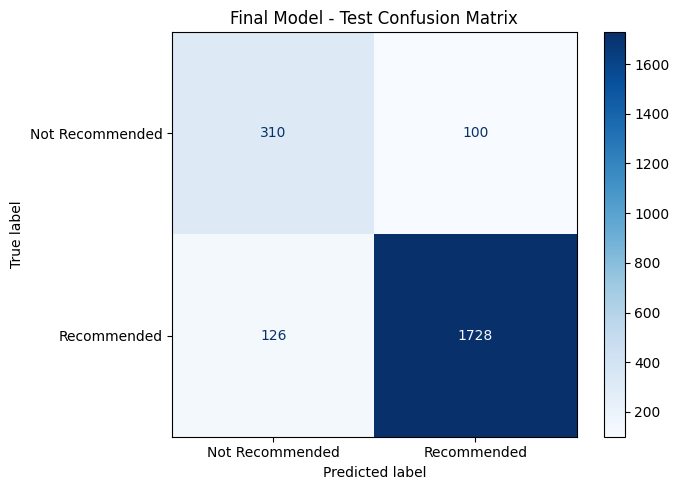

In [78]:
# Final model and fixed threshold
final_model = balanced_pipeline
FINAL_THRESHOLD = 0.40

# Prepare test dataset
X_test = test_df["review_text"]
y_test = test_df["target"].to_numpy()

# Predict probabilities
test_prob = final_model.predict_proba(X_test)

# Get the index of class 1
class_1_idx = np.where(
    final_model.classes_ == 1
)[0][0]

test_prob_recommended = test_prob[:, class_1_idx]

# Apply the selected threshold
test_pred = (
    test_prob_recommended >= FINAL_THRESHOLD
).astype(int)

# Calculate final metrics
test_accuracy = accuracy_score(
    y_test,
    test_pred
)

test_macro_f1 = f1_score(
    y_test,
    test_pred,
    average="macro"
)

test_class_0_recall = recall_score(
    y_test,
    test_pred,
    pos_label=0
)

# Display results
print("FINAL TEST EVALUATION")
print("-" * 35)

print(f"Test Samples: {len(y_test)}")
print(f"Threshold: {FINAL_THRESHOLD:.2f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro F1: {test_macro_f1:.4f}")
print(f"Class 0 Recall: {test_class_0_recall:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=[
            "Not Recommended",
            "Recommended"
        ],
        digits=4,
        zero_division=0
    )
)

# Confusion Matrix
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    labels=[0, 1],
    display_labels=[
        "Not Recommended",
        "Recommended"
    ],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("Final Model - Test Confusion Matrix")

plt.tight_layout()
plt.show()

## 9. Model Serialization and Deployment

### 9.1. Saving the Final Model

After evaluating our final model, we will
save it for future predictions.

We will use joblib to save the trained
Scikit-learn Pipeline.

The Pipeline includes:

- TF-IDF text vectorization.
- Balanced Logistic Regression.

We will also save model metadata, including
the classification threshold and class labels.

This will allow our FastAPI application
to load the model without training it again.

We will use the same preprocessing steps
during training and prediction.

In [80]:
# Model directory
model_dir = project_root / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# File paths
model_path = model_dir / "customer_review_classifier.joblib"
metadata_path = model_dir / "model_metadata.json"

# Save trained pipeline
joblib.dump(
    final_model,
    model_path,
    compress=3
)

# Model metadata
model_metadata = {
    "model_name": "TF-IDF + Balanced Logistic Regression",
    "model_version": "1.0",
    "threshold": FINAL_THRESHOLD,
    "class_labels": {
        "0": "Not Recommended",
        "1": "Recommended"
    },
    "sklearn_version": sklearn.__version__,
    "test_accuracy": round(float(test_accuracy), 4),
    "test_macro_f1": round(float(test_macro_f1), 4)
}

# Save metadata
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(
        model_metadata,
        f,
        indent=4
    )

print("Model saved:", model_path)
print("Metadata saved:", metadata_path)

Model saved: c:\Users\okand\Desktop\Projects\nlp-customer-review-classifier\models\customer_review_classifier.joblib
Metadata saved: c:\Users\okand\Desktop\Projects\nlp-customer-review-classifier\models\model_metadata.json


In [81]:
# Load saved model
loaded_model = joblib.load(model_path)

# Load metadata
with open(metadata_path, "r", encoding="utf-8") as f:
    loaded_metadata = json.load(f)

# Make a sample prediction
sample_text = ["I really love this dress."]

probability = loaded_model.predict_proba(
    sample_text
)[0, 1]

threshold = loaded_metadata["threshold"]

prediction = int(probability >= threshold)

print("Review:", sample_text[0])
print("Recommended Probability:", round(probability, 4))
print("Prediction:", prediction)
print(
    "Label:",
    loaded_metadata["class_labels"][str(prediction)]
)

Review: I really love this dress.
Recommended Probability: 0.9488
Prediction: 1
Label: Recommended
